# SentinelDrift — Phase 4: Explainability

**Purpose:** For each detected drift event, explain which aspects are driving the change.
This is the actionable industrial output of the pipeline.

**Structure:**
- Act 1: Setup & Data Loading
- Act 2: Sanity Checks & Global Context
- Act 3: Explainability Primitives Validation (Nexus 6P single event)
- Act 4: Deep Case Studies — All 6 Products
- Act 5: Cross-Product Synthesis & Industrial Application
- Act 6: Limitations, Reflection & Export

In [1]:
# Self-contained bootstrap (WM9B7 AIDL FAQ compliance)
# Auto-runs upstream phase notebooks if their outputs are missing so this
# notebook is runnable end-to-end with no manual step. Set
# SENTINELDRIFT_SKIP_BOOTSTRAP=1 to bypass during interactive development.
import os, sys
from pathlib import Path

_nb_dir = Path(os.getcwd()).resolve()
_root = _nb_dir if (_nb_dir / "src" / "bootstrap.py").exists() else _nb_dir.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.bootstrap import ensure_inputs  # noqa: E402
ensure_inputs(for_phase="04_explainability")


[bootstrap] skipped (SENTINELDRIFT_SKIP_BOOTSTRAP=1)


In [2]:
import sys
import os
sys.path.insert(0, "..")
os.environ["PYTHONIOENCODING"] = "utf-8"

import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import torch
from pathlib import Path

from src.utils import DATA_PROCESSED, DATA_TIMESERIES, RESULTS_DIR, MODELS_DIR, DASHBOARD_DATA
from src.explain.aspect_delta import (
    compute_event_delta, rank_aspects, compute_all_events,
    bootstrap_delta_ci, random_window_null,
)
from src.explain.recon_decompose import (
    decompose_recon_error, compare_delta_recon, decompose_all_events,
)
from src.explain.review_evidence import select_quotes, keyword_evidence, NEXUS_6P_KEYWORDS
from src.explain.export import build_product_result, export_results
from src.drift.lstm_ae import LSTMAutoencoder, SentimentWindowDataset, score_anomalies, collate_fn
from src.drift.pelt import detect_pelt_product, fuse_events as pelt_fuse
from src.drift.cusum import detect_cusum_product, fuse_events as cusum_fuse
from torch.utils.data import DataLoader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE} | PyTorch: {torch.__version__}")


Device: cuda | PyTorch: 2.10.0+cu128


In [3]:
# Load Phase 2 data
monthly_df = pd.read_parquet(DATA_TIMESERIES / "aspect_sentiment_monthly.parquet")

# Load ABSA data (Phase 1)
absa_df = pd.read_parquet(DATA_PROCESSED / "review_aspect_sentiment.parquet")

# Load reviews (for quote selection)
reviews_path = DATA_PROCESSED / "smartphone_reviews_clean.parquet"
if reviews_path.exists():
    reviews_df = pd.read_parquet(reviews_path,
        columns=["parent_asin", "timestamp", "rating", "review_text_combined", "verified_purchase"])
else:
    print("WARNING: smartphone_reviews_clean.parquet not found -- quotes will be unavailable.")
    reviews_df = pd.DataFrame(
        columns=["parent_asin", "timestamp", "rating", "review_text_combined", "verified_purchase"]
    )

# Load review scaffold (bridges review_pk between reviews and ABSA)
scaffold_path = DATA_PROCESSED / "review_scaffold.parquet"
if scaffold_path.exists():
    scaffold_df = pd.read_parquet(scaffold_path)
else:
    print("WARNING: review_scaffold.parquet not found -- quote selection will be unavailable.")
    scaffold_df = pd.DataFrame(columns=["review_pk", "parent_asin", "timestamp"])

# Case study ASINs
case_asins = Path(DATA_PROCESSED / "case_study_asins.txt").read_text(encoding="utf-8").strip().split("\n")
CONTROL_ASIN = "B01MPXRXR0"
ALL_ASINS = case_asins + [CONTROL_ASIN]

ASPECTS = [
    "audio", "battery", "build", "camera", "charging",
    "connectivity", "display", "performance", "software",
]

PRODUCT_NAMES = {
    "B019BX7F86": "Google Nexus 6P",
    "B07HD2X91Q": "Samsung Galaxy S9+",
    "B0178GE72K": "Samsung Galaxy S6",
    "B0178GE4FU": "Samsung Galaxy S6 Edge",
    "B00OL4DEMC": "LG G3",
    "B01MPXRXR0": "Control (Anker PowerCore)",
}

print(f"monthly_df:  {monthly_df.shape[0]:,} rows, {monthly_df.parent_asin.nunique()} products")
print(f"absa_df:     {absa_df.shape[0]:,} rows")
print(f"reviews_df:  {reviews_df.shape[0]:,} rows")
print(f"scaffold_df: {scaffold_df.shape[0]:,} rows")
print(f"Case ASINs:  {case_asins}")


monthly_df:  193,410 rows, 335 products
absa_df:     387,468 rows
reviews_df:  318,361 rows
scaffold_df: 149,227 rows
Case ASINs:  ['B019BX7F86', 'B07HD2X91Q', 'B0178GE72K', 'B0178GE4FU', 'B00OL4DEMC']


In [4]:
# Load LSTM-AE checkpoint
model = LSTMAutoencoder(input_dim=18, output_dim=9, hidden_dim=32, latent_dim=8)
ckpt_path = MODELS_DIR / "drift" / "lstm_ae" / "best_lstm_ae.pt"
state = torch.load(ckpt_path, map_location=DEVICE, weights_only=True)
model.load_state_dict(state)
model = model.to(DEVICE).eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"LSTM-AE loaded: {ckpt_path.name}  ({n_params:,} parameters)")


LSTM-AE loaded: best_lstm_ae.pt  (15,953 parameters)

In [5]:
# Re-run all 3 detectors on ALL_ASINS
# NOTE: Notebook 03 does not persist per-product event lists — only metrics.json.
# We must re-run detection here to get event_month values for explainability.

def run_detectors(asin, monthly_df, aspects, model, device):
    """Run PELT, CUSUM, LSTM-AE on one product. Return list of event dicts."""
    prod_df = monthly_df[monthly_df["parent_asin"] == asin]
    if len(prod_df) == 0:
        return []

    events = []

    # CUSUM
    try:
        cusum_det = detect_cusum_product(prod_df, aspects)
        cusum_fused = cusum_fuse(cusum_det)
        for _, ev in cusum_fused.iterrows():
            events.append({"parent_asin": asin, "event_month": ev["event_month"], "detector": "CUSUM"})
    except Exception as e:
        print(f"  CUSUM error {asin}: {e}")

    # PELT
    try:
        pelt_det = detect_pelt_product(prod_df, aspects)
        pelt_fused = pelt_fuse(pelt_det)
        for _, ev in pelt_fused.iterrows():
            events.append({"parent_asin": asin, "event_month": ev["event_month"], "detector": "PELT"})
    except Exception as e:
        print(f"  PELT error {asin}: {e}")

    # LSTM-AE
    try:
        dataset = SentimentWindowDataset(
            {asin: prod_df}, aspects, seq_len=6, stride=1
        )
        if len(dataset) > 0:
            ae_scores = score_anomalies(model, dataset, device=device)
            anomaly_rows = ae_scores[ae_scores["is_anomaly"]].sort_values("last_month")
            # Fuse consecutive anomaly months (gap > 2 months = new event)
            fused_ae = []
            for _, row in anomaly_rows.iterrows():
                m = row["last_month"]
                if not fused_ae:
                    fused_ae.append(m)
                else:
                    prev = fused_ae[-1]
                    gap = abs((pd.Period(pd.Timestamp(m), freq="M") -
                               pd.Period(pd.Timestamp(prev), freq="M")).n)
                    if gap > 2:
                        fused_ae.append(m)
            for em in fused_ae:
                events.append({"parent_asin": asin, "event_month": em, "detector": "LSTM-AE"})
    except Exception as e:
        print(f"  LSTM-AE error {asin}: {e}")

    return events


print("Running detectors on all ASINs...")
all_events = []
for asin in ALL_ASINS:
    asin_events = run_detectors(asin, monthly_df, ASPECTS, model, DEVICE)
    all_events.extend(asin_events)
    print(f"  {asin} ({PRODUCT_NAMES.get(asin, asin)}): {len(asin_events)} events")

events_df = pd.DataFrame(all_events)
print(f"\nTotal events: {len(events_df)}")
print(events_df.groupby("detector").size().to_string())


Running detectors on all ASINs...


  B019BX7F86 (Google Nexus 6P): 14 events
  B07HD2X91Q (Samsung Galaxy S9+): 9 events
  B0178GE72K (Samsung Galaxy S6): 6 events


  B0178GE4FU (Samsung Galaxy S6 Edge): 3 events
  B00OL4DEMC (LG G3): 4 events


  B01MPXRXR0 (Control (Anker PowerCore)): 7 events

Total events: 43
detector
CUSUM      23
LSTM-AE     9
PELT       11


In [6]:
# Save detection events for downstream analysis
(RESULTS_DIR / "explainability").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "explainability" / "figures").mkdir(parents=True, exist_ok=True)
events_df.to_parquet(RESULTS_DIR / "explainability" / "detection_events.parquet")
print("Saved detection_events.parquet")
print(f"Created {RESULTS_DIR / 'explainability' / 'figures'}")


Saved detection_events.parquet
Created C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\figures


---
## Act 2: Sanity Checks & Global Context

Before explaining anything, we establish data quality:
1. Aspect coverage heatmap per product
2. Review volume over time
3. Global null delta distribution (expected centred at 0)
4. Detection event summary table


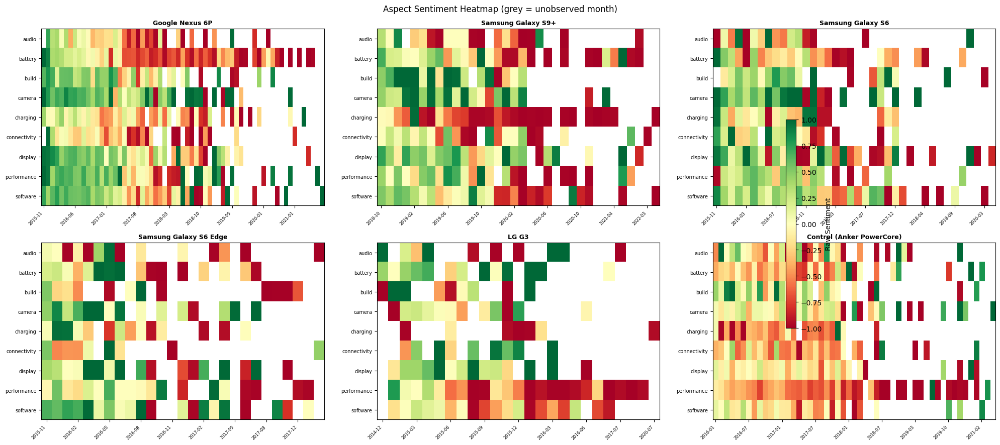

In [7]:
# Aspect coverage heatmap
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
axes = axes.flatten()
for i, asin in enumerate(ALL_ASINS):
    ax = axes[i]
    prod = monthly_df[monthly_df["parent_asin"] == asin].copy()
    prod["_ym"] = prod["year_month"].dt.to_period("M").astype(str)
    pivot = prod.pivot_table(
        index="canonical_aspect", columns="_ym",
        values="raw_mean_sentiment", aggfunc="first"
    )
    # Sort columns chronologically
    pivot = pivot.reindex(sorted(pivot.columns), axis=1)
    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=-1, vmax=1)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=7)
    n_cols = len(pivot.columns)
    tick_step = max(1, n_cols // 8)
    ax.set_xticks(range(0, n_cols, tick_step))
    ax.set_xticklabels(pivot.columns[::tick_step], rotation=45, fontsize=6, ha="right")
    ax.set_title(PRODUCT_NAMES.get(asin, asin), fontsize=9, fontweight="bold")
plt.colorbar(im, ax=axes[:6], shrink=0.6, label="Raw Sentiment")
fig.suptitle("Aspect Sentiment Heatmap (grey = unobserved month)", fontsize=12)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "explainability/figures/heatmap_all_products.png", dpi=120, bbox_inches="tight")
plt.show()


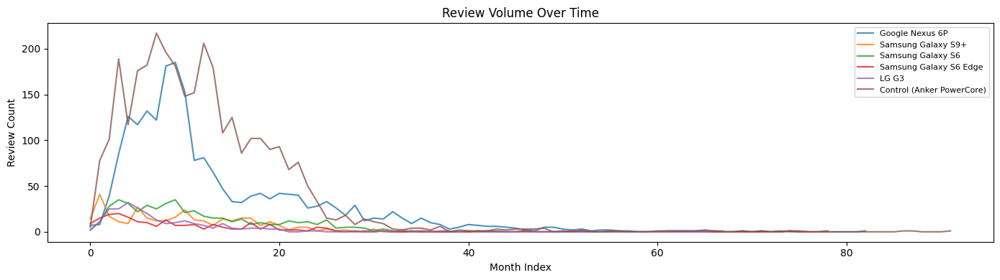

In [8]:
# Review volume over time
fig, ax = plt.subplots(figsize=(14, 4))
for asin in ALL_ASINS:
    prod = monthly_df[monthly_df["parent_asin"] == asin].copy()
    prod["_ym"] = prod["year_month"].dt.to_period("M")
    vol = prod.groupby("_ym")["review_count"].first().sort_index()
    ax.plot(range(len(vol)), vol.values, label=PRODUCT_NAMES.get(asin, asin), alpha=0.8)
ax.set_title("Review Volume Over Time")
ax.set_xlabel("Month Index")
ax.set_ylabel("Review Count")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


Sampling null distribution from 30 random products...


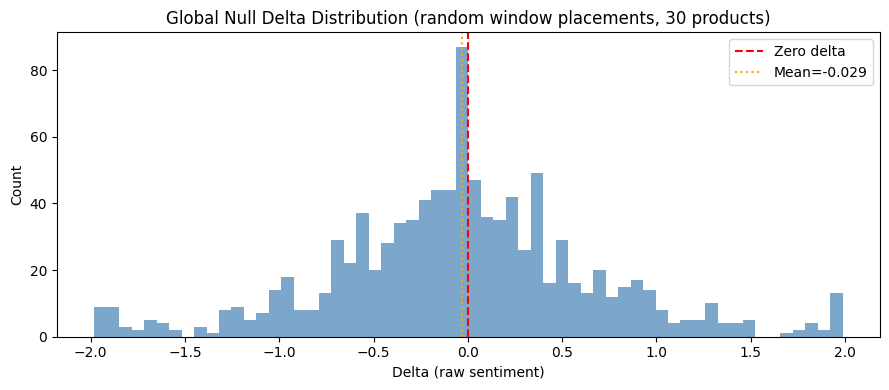

Null delta: mean=-0.0291, std=0.7079


In [9]:
# Global null delta distribution — expected centred near 0
print("Sampling null distribution from 30 random products...")
sample_products = monthly_df["parent_asin"].unique()[:30]
null_all = []
for asin in sample_products:
    null_df = random_window_null(monthly_df, asin, ASPECTS, window=3, n_samples=15)
    null_all.append(null_df)
null_all = pd.concat(null_all, ignore_index=True)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(null_all["delta"].dropna(), bins=60, color="steelblue", alpha=0.7, edgecolor="none")
ax.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero delta")
ax.axvline(null_all["delta"].mean(), color="orange", linestyle=":", linewidth=1.5,
           label=f"Mean={null_all['delta'].mean():.3f}")
ax.set_title("Global Null Delta Distribution (random window placements, 30 products)")
ax.set_xlabel("Delta (raw sentiment)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "explainability/figures/null_delta_dist.png", dpi=120)
plt.show()
print(f"Null delta: mean={null_all['delta'].mean():.4f}, std={null_all['delta'].std():.4f}")


In [10]:
# Detection event summary table
if len(events_df) > 0:
    summary_tbl = events_df.groupby(["parent_asin", "detector"]).size().unstack(fill_value=0)
    summary_tbl.index = [PRODUCT_NAMES.get(a, a) for a in summary_tbl.index]
    display(summary_tbl.style
            .background_gradient(cmap="Blues")
            .set_caption("Events Detected Per Product Per Detector"))
else:
    print("No events detected.")


detector,CUSUM,LSTM-AE,PELT
LG G3,2,1,1
Samsung Galaxy S6 Edge,1,1,1
Samsung Galaxy S6,2,2,2
Google Nexus 6P,9,2,3
Control (Anker PowerCore),3,2,2
Samsung Galaxy S9+,6,1,2


---
## Act 3: Explainability Primitives — Validation on Nexus 6P

We walk through the explainability pipeline on a single well-understood event
before scaling to all products. The Nexus 6P experienced a known hardware issue
(bootloop/battery failure in late 2016–2017) which gives us ground truth.


In [11]:
NEXUS = "B019BX7F86"
nexus_events = events_df[events_df["parent_asin"] == NEXUS].sort_values("event_month")
print("Nexus 6P detected events:")
display(nexus_events)

# Use the first CUSUM event (most likely to align with hardware issue)
cusum_nexus = nexus_events[nexus_events["detector"] == "CUSUM"]
ev_month = (
    cusum_nexus.iloc[0]["event_month"]
    if len(cusum_nexus) > 0
    else nexus_events.iloc[0]["event_month"] if len(nexus_events) > 0
    else pd.Timestamp("2017-01-01")
)
print(f"\nWalkthrough event: {ev_month}")


Nexus 6P detected events:


,parent_asin,event_month,detector
0,B019BX7F86,2016-01-01,CUSUM
1,B019BX7F86,2016-06-01,CUSUM
2,B019BX7F86,2016-09-01,CUSUM
9,B019BX7F86,2016-09-01,PELT
10,B019BX7F86,2016-12-01,PELT
3,B019BX7F86,2017-02-01,CUSUM
4,B019BX7F86,2017-04-01,CUSUM
11,B019BX7F86,2017-04-01,PELT
5,B019BX7F86,2017-07-01,CUSUM
12,B019BX7F86,2017-12-01,LSTM-AE



Walkthrough event: 2016-01-01 00:00:00


In [12]:
# Delta walkthrough
deltas_nexus = compute_event_delta(monthly_df, NEXUS, ev_month, ASPECTS, window=3)
ranked_nexus = rank_aspects(deltas_nexus)
print("Nexus 6P aspect delta ranking:")
display(ranked_nexus[["canonical_aspect", "pre_mean", "post_mean", "delta",
                        "abs_delta", "confidence", "coverage"]].head(5))


Nexus 6P aspect delta ranking:


,canonical_aspect,pre_mean,post_mean,delta,abs_delta,confidence,coverage
0,connectivity,0.983655,0.079615,-0.904040,0.904040,low,0.666667
1,battery,0.944041,0.374124,-0.569917,0.569917,high,0.833333
2,audio,0.729118,0.250881,-0.478237,0.478237,low,0.666667
3,performance,0.957107,0.591763,-0.365345,0.365345,high,0.833333
4,display,0.945152,0.683908,-0.261244,0.261244,high,0.833333


In [13]:
# LSTM-AE decomposition walkthrough
recon_nexus = decompose_recon_error(
    model, monthly_df, NEXUS, ev_month, ASPECTS, seq_len=6, device=DEVICE
)
print("Nexus 6P LSTM-AE reconstruction decomposition:")
display(recon_nexus.sort_values("contribution_pct", ascending=False))

agreement_nexus = compare_delta_recon(ranked_nexus, recon_nexus, top_k=3)
print(f"\nAgreement: {agreement_nexus['agreement'].upper()}")
print(f"  Top-3 delta: {agreement_nexus['top_k_delta']}")
print(f"  Top-3 recon: {agreement_nexus['top_k_recon']}")
print(f"  Overlap: {agreement_nexus['overlap_aspects']}")
print(f"  {agreement_nexus['interpretation']}")


Nexus 6P LSTM-AE reconstruction decomposition:

,canonical_aspect,recon_error,mask,contribution_pct
5,connectivity,15.924663,True,76.879364
7,performance,1.598256,True,7.715887
3,camera,1.403451,True,6.775431
8,software,0.511060,True,2.467240
0,audio,0.479477,True,2.314768
1,battery,0.451620,True,2.180283
4,charging,0.209977,True,1.013702
2,build,0.128929,True,0.622432
6,display,0.006399,True,0.030893



Agreement: PARTIAL
  Top-3 delta: ['connectivity', 'battery', 'audio']
  Top-3 recon: ['connectivity', 'performance', 'camera']
  Overlap: ['connectivity']
  Partial agreement (Spearman rho=0.333, top-3 overlap=1/3): LSTM-AE detects related but not identical aspect patterns, possibly capturing temporal dynamics beyond level shifts.


### Methodology Note

We use **aspect-level sentiment delta** as the primary explainability signal rather
than Captum Integrated Gradients (IG). Justification:

1. **Semantic directness:** PyABSA already produces aspect-level features. Delta is
   directly interpretable: "battery sentiment fell 0.28 points post-event."
2. **Captum IG would attribute within the detector architecture**, not within the
   ABSA extractor where linguistic meaning originates.
3. **Review quotes** provide human-readable confirmation without gradient attribution.

LSTM-AE reconstruction decomposition is a **complementary signal** — it detects
aspects anomalous in the latent representation, which may differ from level-shift
detection. CUSUM confirms level; LSTM-AE detects shape/volatility changes.


In [14]:
# Nexus 6P — bootstrap CI on top-3 aspects (flagship rigor)
top3_aspects = ranked_nexus.head(3)["canonical_aspect"].tolist()
print(f"Bootstrap 95% CIs for Nexus 6P event {ev_month} (window=3, n_boot=1000)")
for asp in top3_aspects:
    ci = bootstrap_delta_ci(absa_df, NEXUS, ev_month, asp, window=3, n_boot=1000)
    ci_str = (
        f"[{ci['ci_lower']:+.3f}, {ci['ci_upper']:+.3f}]"
        if ci["ci_lower"] is not None and not np.isnan(ci["ci_lower"])
        else "[insufficient data]"
    )
    crosses_zero = (
        ci["ci_lower"] < 0 < ci["ci_upper"]
        if ci["ci_lower"] is not None and not np.isnan(ci["ci_lower"])
        else None
    )
    print(f"  {asp:15s}: delta={ci['delta']:+.3f}  95% CI {ci_str}  "
          f"n_pre={ci['n_reviews_pre']}, n_post={ci['n_reviews_post']}  "
          f"crosses_zero={crosses_zero}")


Bootstrap 95% CIs for Nexus 6P event 2016-01-01 00:00:00 (window=3, n_boot=1000)
  connectivity   : delta=-0.500  95% CI [-1.084, +0.084]  n_pre=2, n_post=62  crosses_zero=True


  battery        : delta=-0.388  95% CI [-0.646, -0.045]  n_pre=14, n_post=152  crosses_zero=False


  audio          : delta=-0.163  95% CI [-0.801, +0.458]  n_pre=8, n_post=64  crosses_zero=True


---
## Act 4: Deep Case Studies — All 6 Products

For each product we run a standardised **6-panel analysis** per detected event:
1. Annotated sentiment timeline with drift event markers
2. Aspect delta ranking (red = deterioration, green = improvement)
3. LSTM-AE reconstruction error contribution
4. Delta vs LSTM-AE agreement
5. Review text evidence (representative + extreme quotes)
6. Narrative & action items

Nexus 6P additionally receives: bootstrap CIs, random-window null comparison,
window sensitivity check.


In [15]:
# Helper: 6-panel figure
def plot_6_panels(asin, ev_month, monthly_df, events_df, deltas, recon, quotes_df, agreement):
    """Generate 6-panel explainability figure for one product + event."""
    prod_name = PRODUCT_NAMES.get(asin, asin)
    prod_monthly = monthly_df[monthly_df["parent_asin"] == asin].copy()
    prod_monthly["_ym"] = prod_monthly["year_month"].dt.to_period("M")
    months_sorted = sorted(prod_monthly["_ym"].unique())
    ev_period = pd.Period(pd.Timestamp(ev_month), freq="M")

    fig = plt.figure(figsize=(20, 22))
    gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.3)

    # Panel 1 — Annotated Timeline (full width)
    ax1 = fig.add_subplot(gs[0, :])
    asp_colors = plt.cm.tab10(np.linspace(0, 1, len(ASPECTS)))
    for j, asp in enumerate(ASPECTS):
        asp_df = prod_monthly[prod_monthly["canonical_aspect"] == asp].set_index("_ym")
        scores = [
            float(asp_df.loc[m, "raw_mean_sentiment"])
            if m in asp_df.index and not pd.isna(asp_df.loc[m, "raw_mean_sentiment"])
            else np.nan
            for m in months_sorted
        ]
        ax1.plot(range(len(months_sorted)), scores, label=asp,
                 color=asp_colors[j], alpha=0.75, linewidth=1.5)

    # Mark all events for this product
    prod_ev = events_df[events_df["parent_asin"] == asin]
    ev_colors = {"CUSUM": "blue", "PELT": "green", "LSTM-AE": "red"}
    for _, ev_row in prod_ev.iterrows():
        ep = pd.Period(pd.Timestamp(ev_row["event_month"]), freq="M")
        if ep in months_sorted:
            xi = months_sorted.index(ep)
            det = ev_row["detector"]
            ax1.axvline(xi, color=ev_colors.get(det, "grey"),
                       linestyle="--" if det == "PELT" else ":",
                       linewidth=1.5, alpha=0.6)

    # Highlight the focal event
    if ev_period in months_sorted:
        ax1.axvline(months_sorted.index(ev_period), color="black",
                   linewidth=2.5, label=f"Focal event ({ev_period})")

    tick_step = max(1, len(months_sorted) // 10)
    ax1.set_xticks(range(0, len(months_sorted), tick_step))
    ax1.set_xticklabels([str(m) for m in months_sorted[::tick_step]],
                        rotation=45, fontsize=8, ha="right")
    ax1.set_ylabel("Raw Sentiment")
    ax1.set_title(f"{prod_name} — Sentiment Timeline", fontsize=11, fontweight="bold")
    ax1.legend(fontsize=7, ncol=5, loc="upper right", framealpha=0.7)

    # Panel 2 — Aspect Delta Ranking
    ax2 = fig.add_subplot(gs[1, 0])
    plot_deltas = deltas.dropna(subset=["delta"]).sort_values("abs_delta")
    bar_colors = ["#ef4444" if d < 0 else "#22c55e" for d in plot_deltas["delta"]]
    bars = ax2.barh(plot_deltas["canonical_aspect"], plot_deltas["delta"], color=bar_colors)
    ax2.axvline(0, color="black", linewidth=0.8)
    for bar, (_, row) in zip(bars, plot_deltas.iterrows()):
        label = f" {row['confidence'][0].upper()} cov={row['coverage']:.1f}"
        x = row["delta"] + (0.005 if row["delta"] >= 0 else -0.005)
        ax2.text(x, bar.get_y() + bar.get_height() / 2, label,
                va="center", fontsize=6.5,
                ha="left" if row["delta"] >= 0 else "right")
    ax2.set_title(f"Aspect {chr(916)} (event: {ev_period})", fontsize=10)
    ax2.set_xlabel("Post − Pre Sentiment (raw)")

    # Panel 3 — LSTM-AE Reconstruction Contribution
    ax3 = fig.add_subplot(gs[1, 1])
    recon_sorted = recon.sort_values("contribution_pct")
    bar_col3 = ["#6366f1" if m else "#9ca3af" for m in recon_sorted["mask"]]
    ax3.barh(recon_sorted["canonical_aspect"], recon_sorted["contribution_pct"], color=bar_col3)
    ax3.set_title("LSTM-AE Recon Contribution %", fontsize=10)
    ax3.set_xlabel("% of anomaly score")
    ax3.text(0.97, 0.02, "grey = unobserved", transform=ax3.transAxes,
             fontsize=7, ha="right", va="bottom", color="grey")

    # Panel 4 — Delta vs Recon Agreement
    ax4 = fig.add_subplot(gs[2, 0])
    ax4.axis("off")
    table_data = [
        ["Top-3 Δ", ", ".join(agreement["top_k_delta"]) or "—"],
        ["Top-3 Recon", ", ".join(agreement["top_k_recon"]) or "—"],
        ["Overlap", f"{agreement['overlap']}: {', '.join(agreement['overlap_aspects']) or 'none'}"],
        ["Agreement", agreement["agreement"].upper()],
        ["Note", agreement["interpretation"][:90] + "…"],
    ]
    tbl = ax4.table(
        cellText=table_data,
        colLabels=["Metric", "Value"],
        loc="center", cellLoc="left",
        colWidths=[0.25, 0.75],
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8)
    tbl[(0, 0)].set_facecolor("#1e3a5f"); tbl[(0, 1)].set_facecolor("#1e3a5f")
    tbl[(0, 0)].set_text_props(color="white"); tbl[(0, 1)].set_text_props(color="white")
    ax4.set_title("Delta vs LSTM-AE Agreement", fontsize=10)

    # Panel 5 — Review Evidence
    ax5 = fig.add_subplot(gs[2, 1])
    ax5.axis("off")
    ev_quotes = quotes_df[
        (quotes_df["parent_asin"] == asin) &
        (quotes_df["event_month"].astype(str) == str(ev_period))
    ].head(4)
    y = 0.95
    if len(ev_quotes) == 0:
        ax5.text(0.02, 0.5, "No quotes available (reviews file not loaded or"
                 "no ABSA matches in post-window).",
                 transform=ax5.transAxes, fontsize=8, va="center", color="grey")
    for _, q in ev_quotes.iterrows():
        snippet = q["review_text_snippet"][:130]
        lbl = f"[{q['canonical_aspect']} / {q['quote_type']}]"
        ax5.text(0.02, y, lbl, transform=ax5.transAxes, fontsize=7.5,
                 fontweight="bold", va="top")
        ax5.text(0.02, y - 0.06, f'"{snippet}..."', transform=ax5.transAxes,
                 fontsize=7, va="top", style="italic", wrap=True,
                 bbox=dict(boxstyle="round,pad=0.2", facecolor="#fef9c3", alpha=0.7))
        y -= 0.26
    ax5.set_title("Review Evidence (post-drift window)", fontsize=10)

    fig.suptitle(
        f"{prod_name} ({asin}) — 6-Panel Explainability"
        f"\nFocal Event: {ev_period}",
        fontsize=13, fontweight="bold"
    )
    fig_path = RESULTS_DIR / f"explainability/figures/{asin}_{ev_period}_6panel.png"
    plt.savefig(fig_path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [16]:
# Helper: full product analysis
def analyze_product(asin, label=None):
    """Run full 6-panel analysis for one product. Returns (result_dict, deltas, recon, quotes)."""
    label = label or PRODUCT_NAMES.get(asin, asin)
    prod_events = events_df[events_df["parent_asin"] == asin]

    print("\n" + "=" * 60)
    print(f"{label} ({asin})")
    print(f"{'='*60}")
    print(f"Detected events: {len(prod_events)}")

    if len(prod_events) == 0:
        print("  No events detected for this product.")
        return None, pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    all_deltas, all_recon_list, all_quotes = [], [], []

    for _, event in prod_events.drop_duplicates("event_month").iterrows():
        ev_month = event["event_month"]
        ev_period = pd.Period(pd.Timestamp(ev_month), freq="M")

        # Aspect delta
        deltas = rank_aspects(
            compute_event_delta(monthly_df, asin, ev_month, ASPECTS, window=3)
        )
        deltas["parent_asin"] = asin
        deltas["event_month"] = str(ev_period)

        # Recon decomposition
        recon = decompose_recon_error(
            model, monthly_df, asin, ev_month, ASPECTS, seq_len=6, device=DEVICE
        )
        recon["parent_asin"] = asin
        recon["event_month"] = str(ev_period)

        # Review quotes (scaffold_df bridges review_pk between reviews and ABSA)
        top_aspects = deltas.head(3)["canonical_aspect"].tolist()
        asp_delta_dict = dict(zip(deltas["canonical_aspect"], deltas["delta"]))
        quotes = select_quotes(
            reviews_df, absa_df, scaffold_df, asin, ev_month,
            top_aspects, window=3, n_quotes=6, aspect_deltas=asp_delta_dict
        )

        # Agreement
        agreement = compare_delta_recon(deltas, recon, top_k=3)

        # Plot
        plot_6_panels(asin, ev_month, monthly_df, events_df,
                      deltas, recon, quotes, agreement)

        all_deltas.append(deltas)
        all_recon_list.append(recon)
        if len(quotes) > 0:
            all_quotes.append(quotes)

        print(f"  Event {ev_period}: top aspect = {deltas.iloc[0]['canonical_aspect']} "
              f"(delta={deltas.iloc[0]['delta']:+.3f}, {deltas.iloc[0]['direction']})")
        print(f"    Agreement: {agreement['agreement']}, overlap: {agreement['overlap_aspects']}")

    all_deltas_df = pd.concat(all_deltas, ignore_index=True)
    all_recon_df = pd.concat(all_recon_list, ignore_index=True) if all_recon_list else pd.DataFrame()
    all_quotes_df = pd.concat(all_quotes, ignore_index=True) if all_quotes else pd.DataFrame()

    result = build_product_result(
        asin, PRODUCT_NAMES.get(asin, asin), prod_events,
        all_deltas_df, all_recon_df, all_quotes_df,
        monthly_df, ASPECTS
    )
    return result, all_deltas_df, all_recon_df, all_quotes_df


In [17]:
# Initialise result collectors — all product analyses append here
all_results = []
all_deltas_combined = []



Google Nexus 6P (B019BX7F86)
Detected events: 14


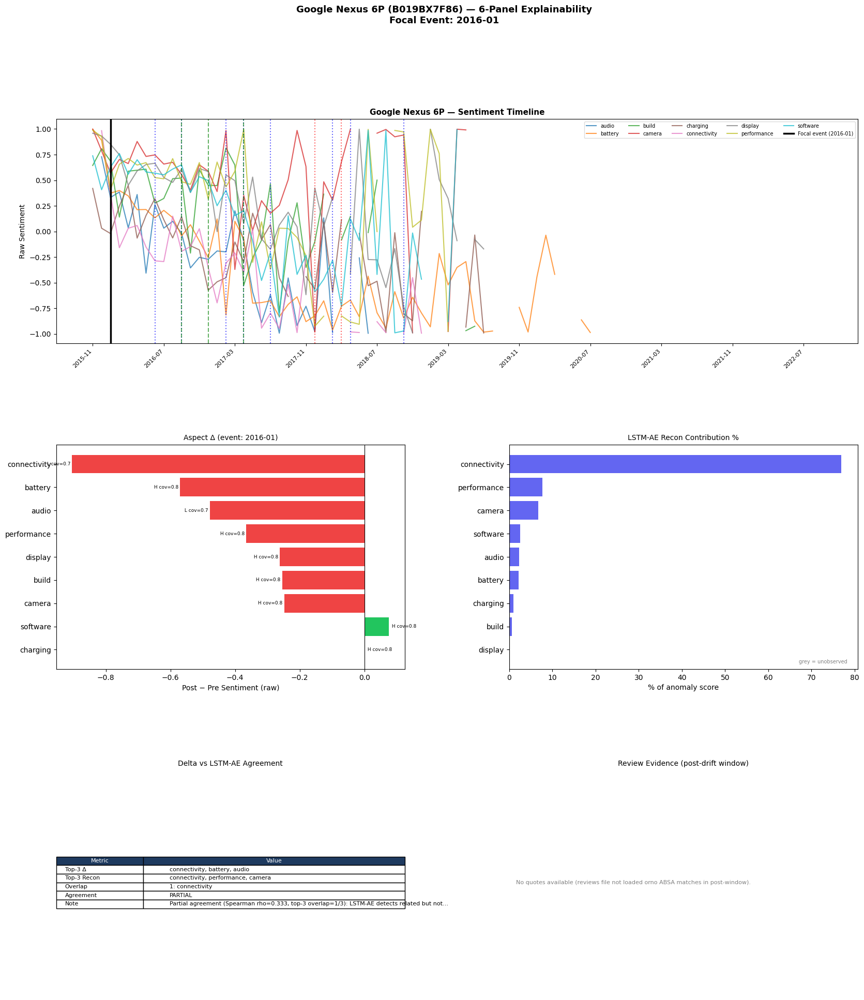

  Event 2016-01: top aspect = connectivity (delta=-0.904, deterioration)
    Agreement: partial, overlap: ['connectivity']


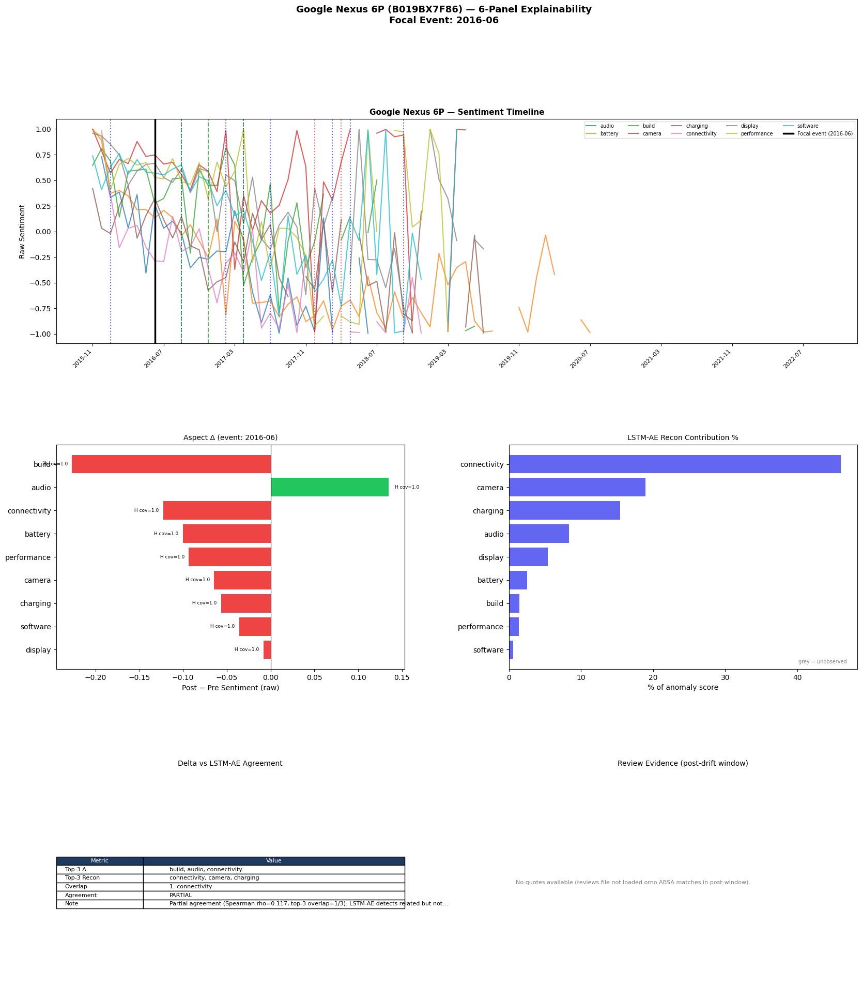

  Event 2016-06: top aspect = build (delta=-0.227, deterioration)
    Agreement: partial, overlap: ['connectivity']


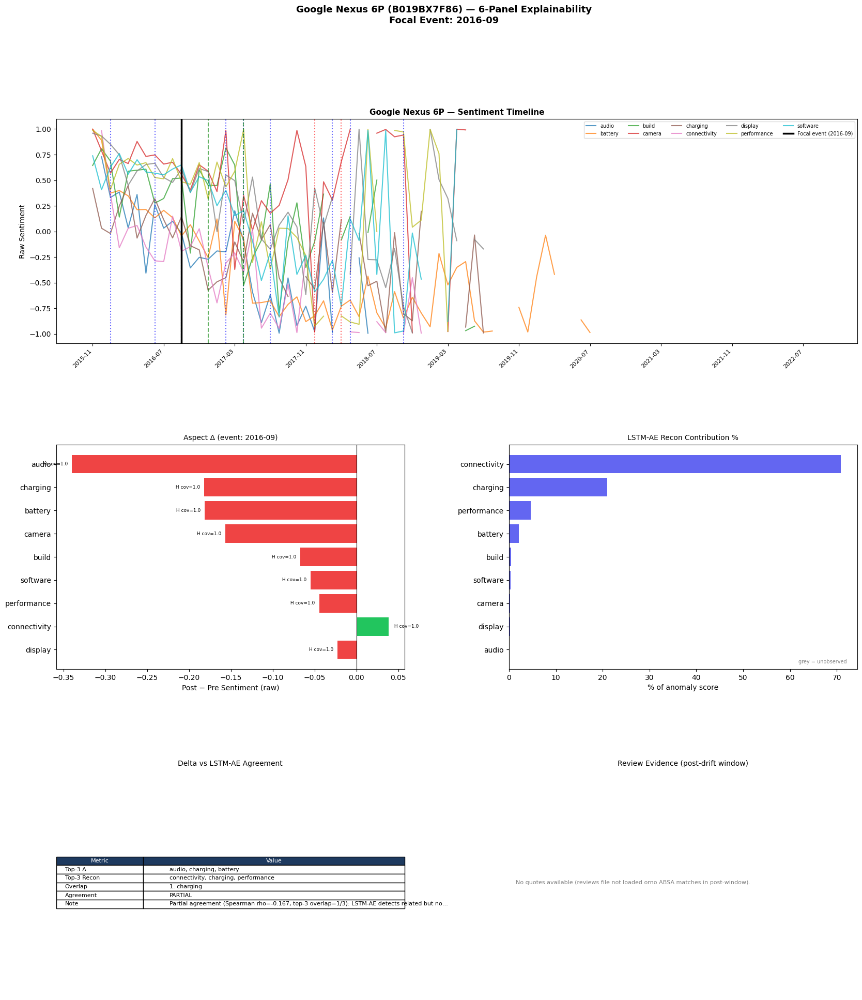

  Event 2016-09: top aspect = audio (delta=-0.340, deterioration)
    Agreement: partial, overlap: ['charging']


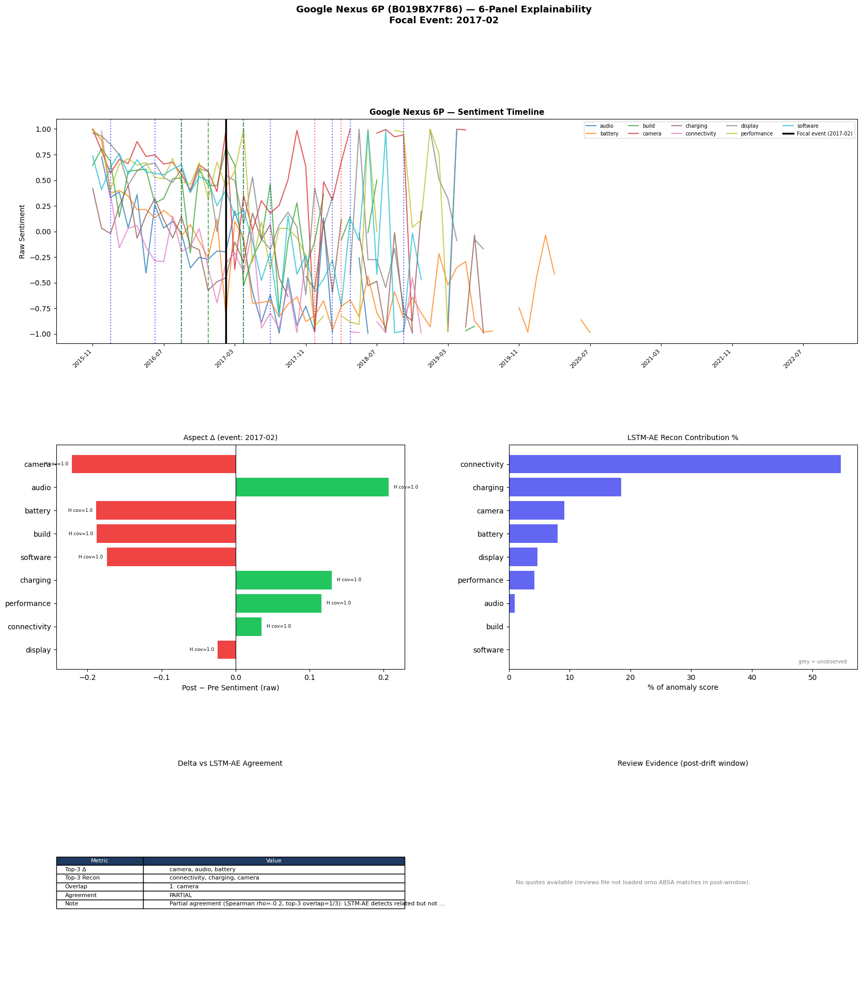

  Event 2017-02: top aspect = camera (delta=-0.221, deterioration)
    Agreement: partial, overlap: ['camera']


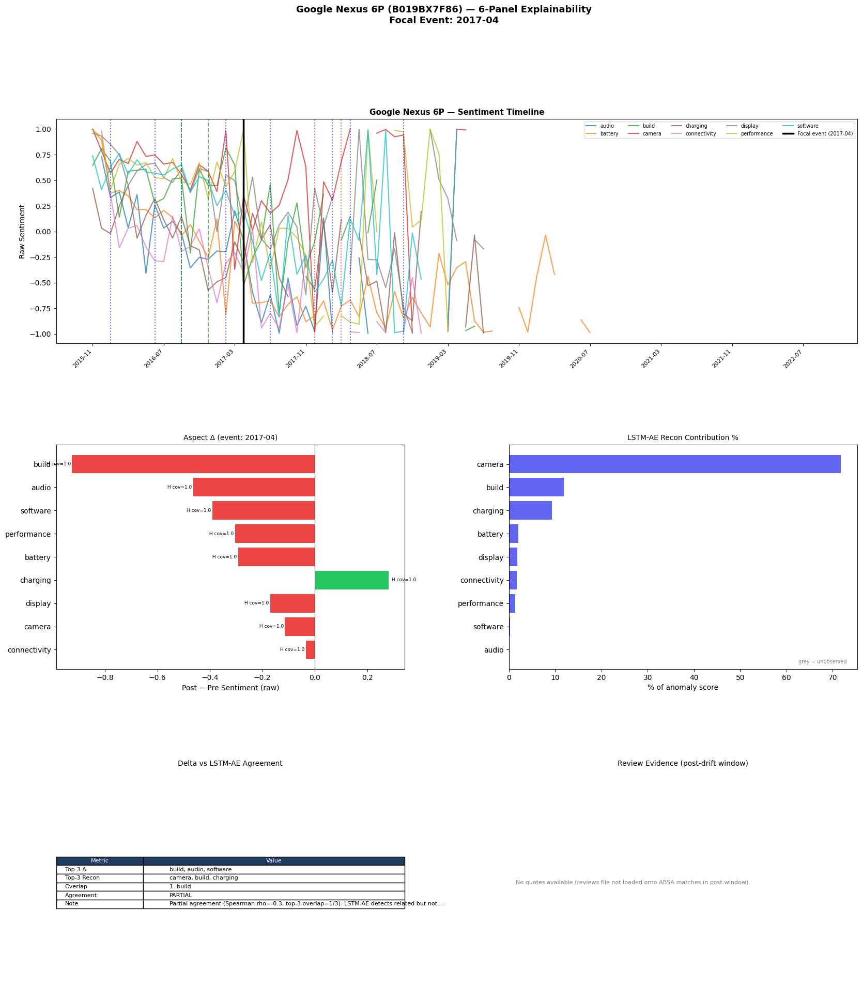

  Event 2017-04: top aspect = build (delta=-0.925, deterioration)
    Agreement: partial, overlap: ['build']


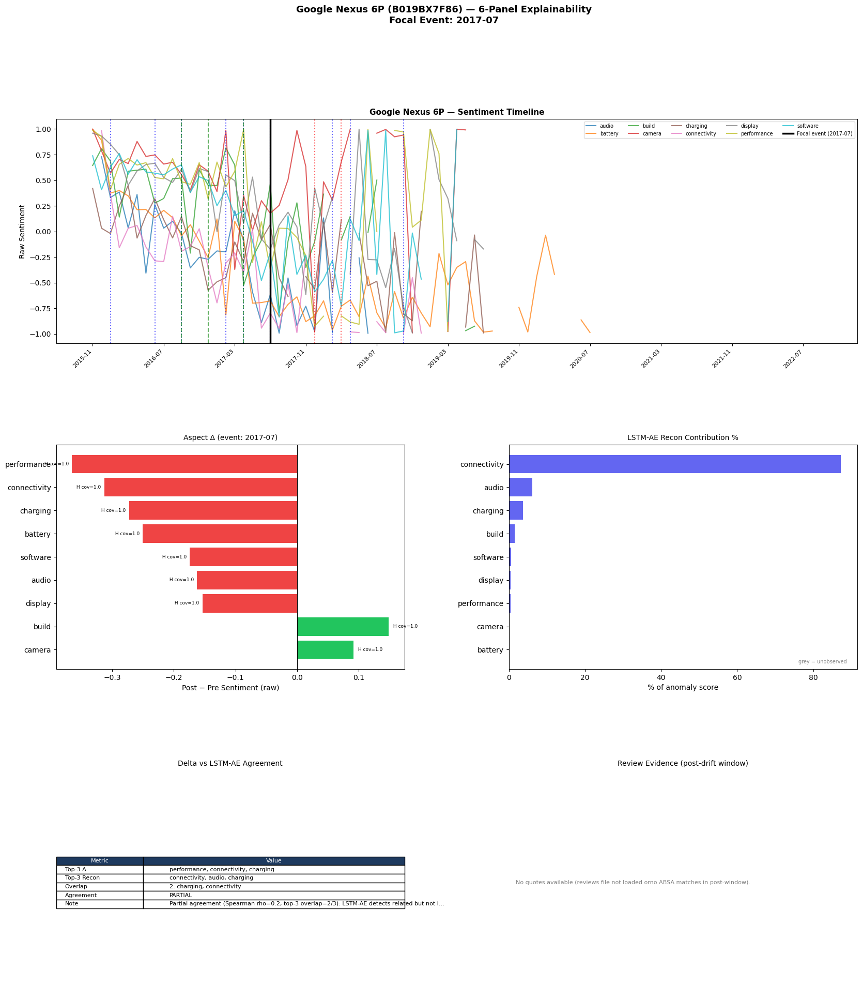

  Event 2017-07: top aspect = performance (delta=-0.365, deterioration)
    Agreement: partial, overlap: ['charging', 'connectivity']


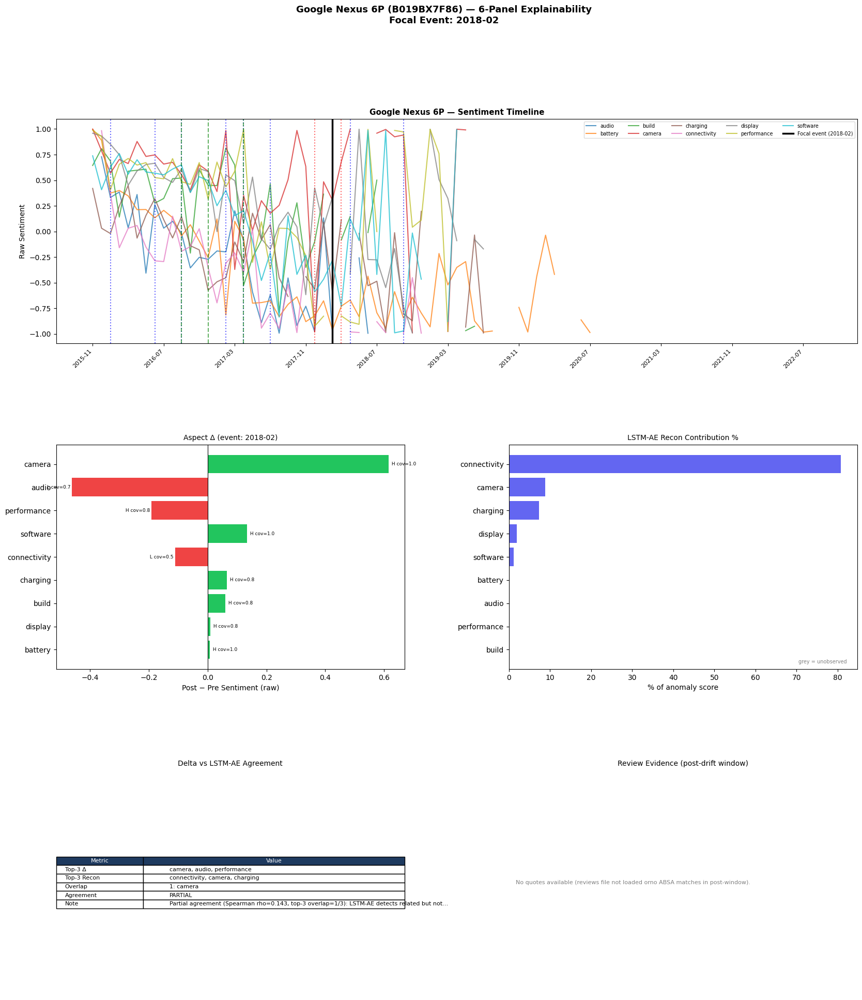

  Event 2018-02: top aspect = camera (delta=+0.616, improvement)
    Agreement: partial, overlap: ['camera']


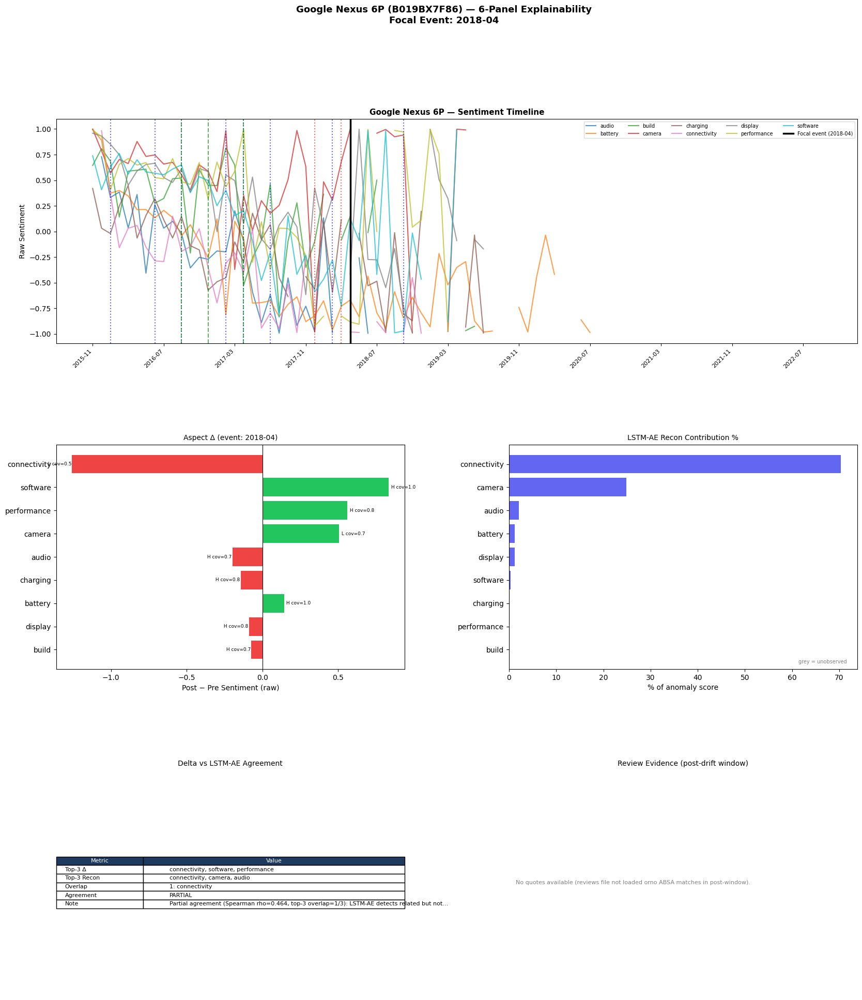

  Event 2018-04: top aspect = connectivity (delta=-1.256, deterioration)
    Agreement: partial, overlap: ['connectivity']


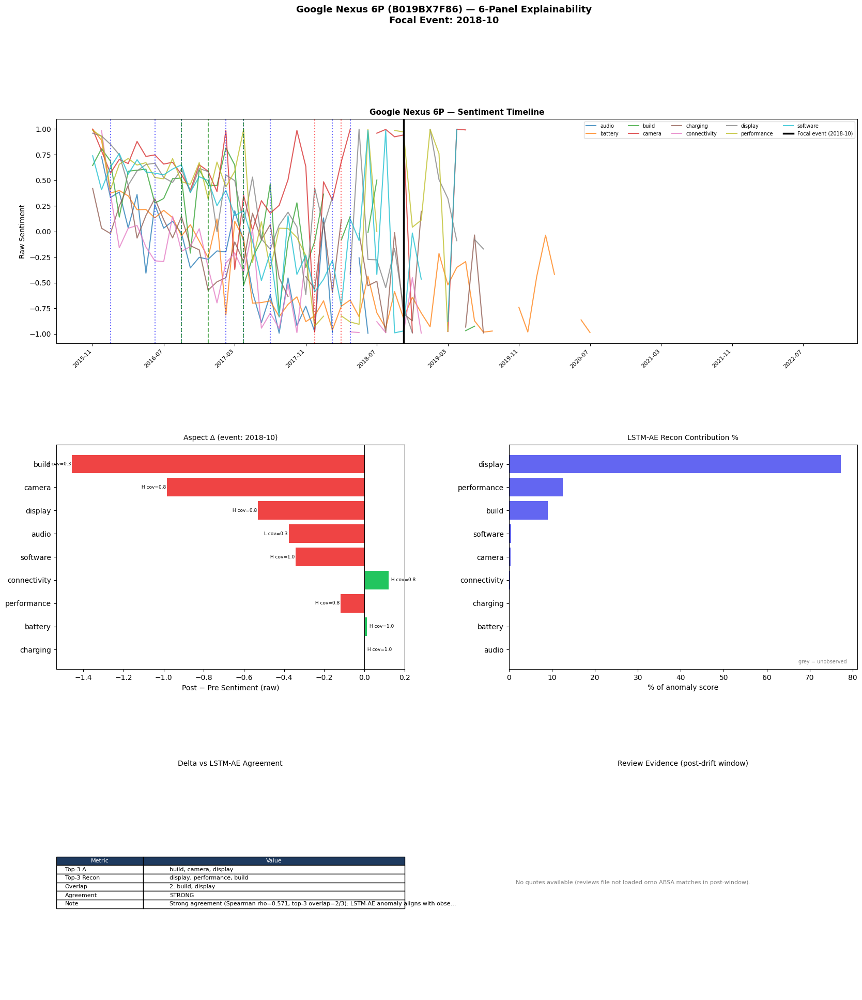

  Event 2018-10: top aspect = build (delta=-1.456, deterioration)
    Agreement: strong, overlap: ['build', 'display']


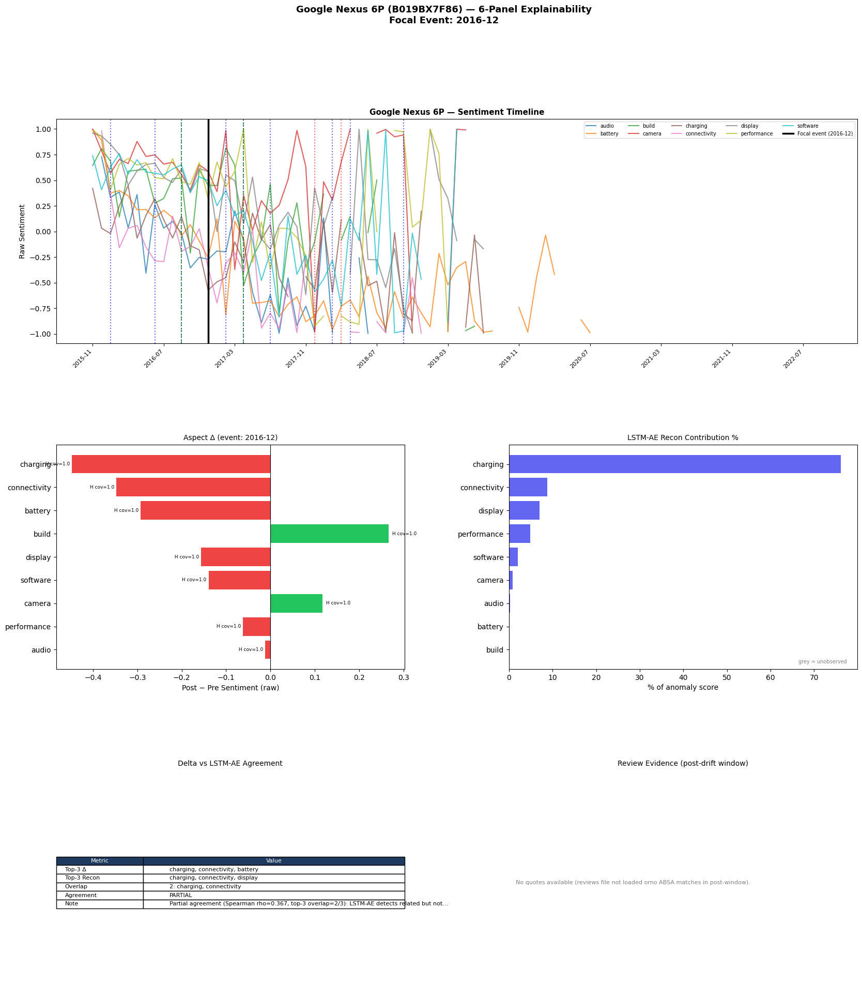

  Event 2016-12: top aspect = charging (delta=-0.447, deterioration)
    Agreement: partial, overlap: ['charging', 'connectivity']


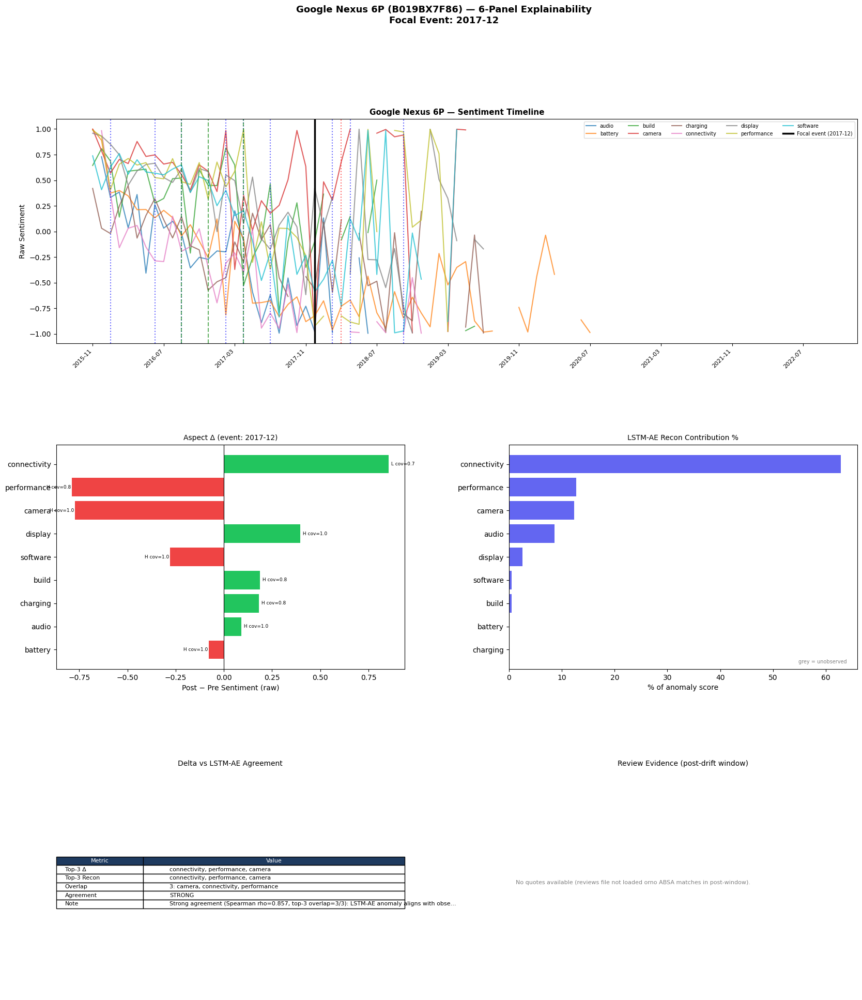

  Event 2017-12: top aspect = connectivity (delta=+0.855, improvement)
    Agreement: strong, overlap: ['camera', 'connectivity', 'performance']


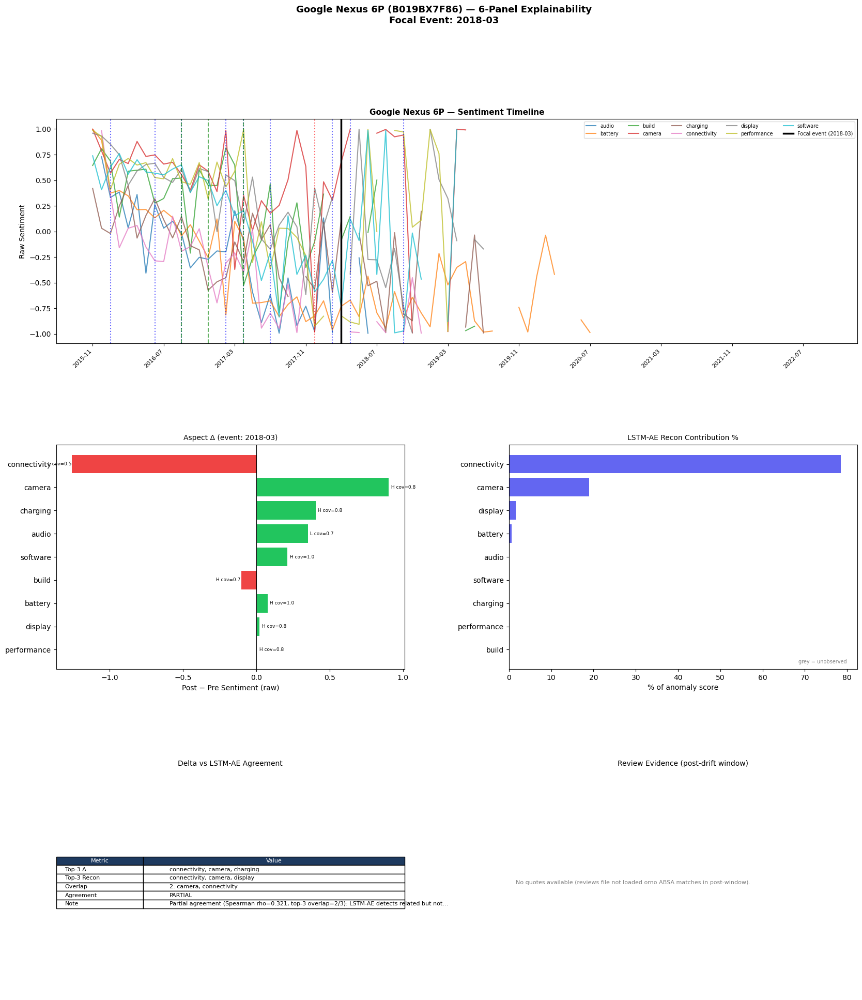

  Event 2018-03: top aspect = connectivity (delta=-1.256, deterioration)
    Agreement: partial, overlap: ['camera', 'connectivity']


In [18]:
# Nexus 6P — full analysis + extra rigor
nexus_result, nexus_deltas, nexus_recon, nexus_quotes = analyze_product("B019BX7F86")
if nexus_result:
    all_results.append(nexus_result)
if len(nexus_deltas) > 0:
    all_deltas_combined.append(nexus_deltas)


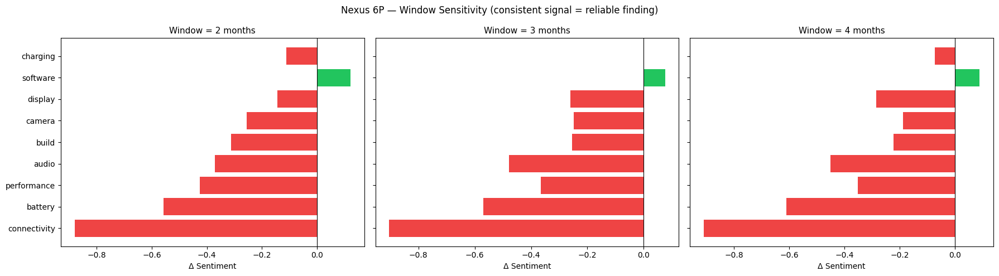

In [19]:
# Nexus 6P — window sensitivity check (w=2,3,4)
nexus_ev_list = events_df[events_df["parent_asin"] == "B019BX7F86"]["event_month"].unique()
ev_primary = nexus_ev_list[0] if len(nexus_ev_list) > 0 else pd.Timestamp("2017-01-01")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, w in zip(axes, [2, 3, 4]):
    d = rank_aspects(compute_event_delta(monthly_df, "B019BX7F86", ev_primary, ASPECTS, window=w))
    colors = ["#ef4444" if x < 0 else "#22c55e" for x in d["delta"].fillna(0)]
    ax.barh(d["canonical_aspect"], d["delta"].fillna(0), color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Window = {w} months", fontsize=11)
    ax.set_xlabel("\u0394 Sentiment")
fig.suptitle("Nexus 6P \u2014 Window Sensitivity (consistent signal = reliable finding)",
             fontsize=12)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "explainability/figures/nexus_window_sensitivity.png", dpi=120)
plt.show()


In [20]:
# Nexus 6P — keyword evidence
ev_p = pd.Period(pd.Timestamp(ev_primary), freq="M")
print(f"Nexus 6P keyword analysis around event {ev_p}")
for kw_group in [
    ["bootloop", "bricked"],
    ["battery drain", "shutdown", "overheat"],
    ["won't turn on", "restart", "freeze"],
]:
    results = keyword_evidence(reviews_df, "B019BX7F86", ev_primary, kw_group, window=3)
    for ev_kw in results:
        pre, post = ev_kw["count_pre"], ev_kw["count_post"]
        ratio = ev_kw["ratio"]
        print(f"  {ev_kw['keyword']}: pre={pre}, post={post}, ratio={ratio:.1f}x")
        if ev_kw["sample_quote"]:
            print(f"    Sample: \"{ev_kw['sample_quote'][:150]}\"")
    print()


Nexus 6P keyword analysis around event 2016-01
  bootloop: pre=0, post=1, ratio=1.0x
    Sample: "Bootloop.. Bootlooping after six months of using."
  bricked: pre=0, post=0, ratio=0.0x

  battery drain: pre=0, post=0, ratio=0.0x
  shutdown: pre=0, post=0, ratio=0.0x
  overheat: pre=1, post=2, ratio=2.0x
    Sample: "By far the best phone I've ever owned. By far the best phone I've ever owned. I omitted one star for two minor issues. It's a bit big but that's expec"

  won't turn on: pre=0, post=0, ratio=0.0x
  restart: pre=0, post=3, ratio=3.0x
    Sample: "5 star phone for the price point! minor hiccups and only a couple major cons when compared to higher price point phones. For the price point this is a"
  freeze: pre=0, post=0, ratio=0.0x



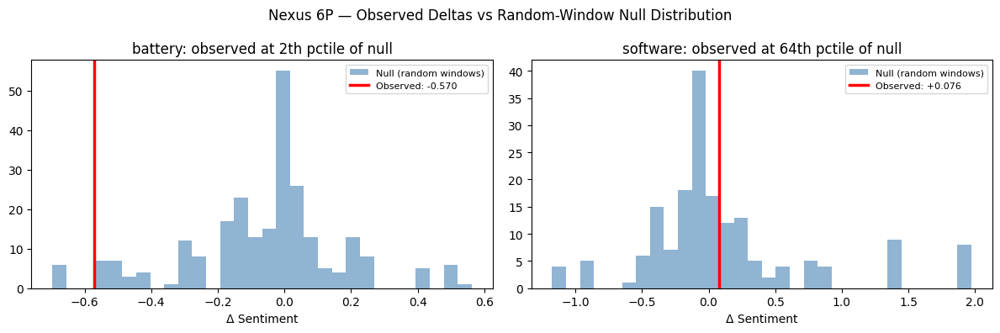

In [21]:
# Nexus 6P — null comparison
null_nexus = random_window_null(monthly_df, "B019BX7F86", ["battery","software"],
                                window=3, n_samples=300)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, asp in zip(axes, ["battery", "software"]):
    nd = null_nexus[null_nexus["canonical_aspect"] == asp]["delta"].dropna()
    ax.hist(nd, bins=30, alpha=0.6, color="steelblue", label="Null (random windows)")

    # Observed delta at primary event
    obs = nexus_deltas[nexus_deltas["canonical_aspect"] == asp]["delta"]
    if len(obs) > 0:
        obs_val = obs.iloc[0]
        ax.axvline(obs_val, color="red", linewidth=2.5, label=f"Observed: {obs_val:+.3f}")

    pct = (nd < obs.iloc[0]).mean() * 100 if len(obs) > 0 else 50
    ax.set_title(f"{asp}: observed at {pct:.0f}th pctile of null")
    ax.set_xlabel("\u0394 Sentiment")
    ax.legend(fontsize=8)

fig.suptitle("Nexus 6P \u2014 Observed Deltas vs Random-Window Null Distribution")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "explainability/figures/nexus_null_comparison.png", dpi=120)
plt.show()



Samsung Galaxy S9+ (B07HD2X91Q)
Detected events: 9


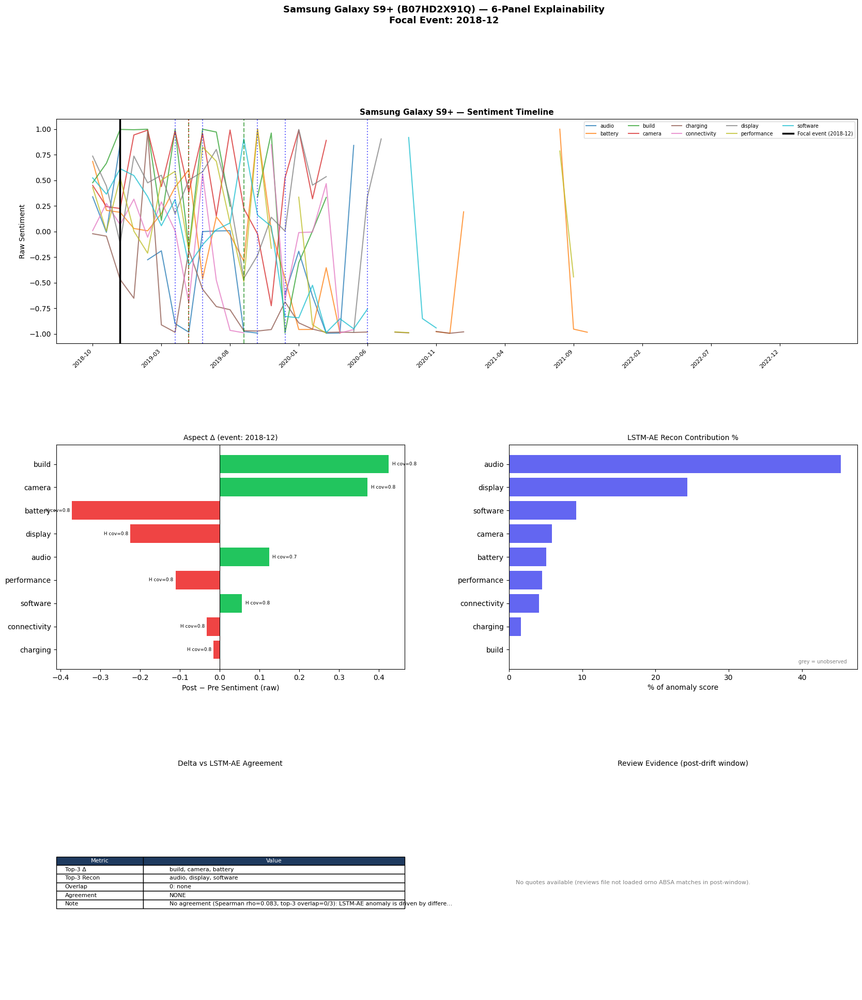

  Event 2018-12: top aspect = build (delta=+0.425, improvement)
    Agreement: none, overlap: []


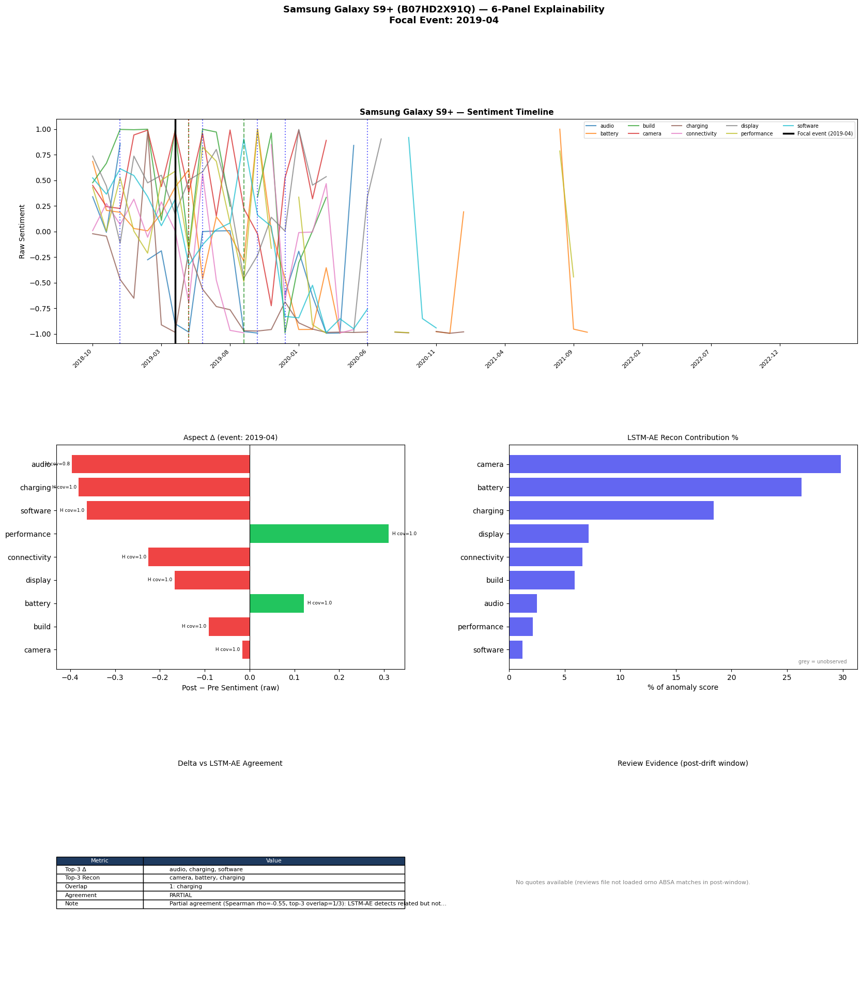

  Event 2019-04: top aspect = audio (delta=-0.396, deterioration)
    Agreement: partial, overlap: ['charging']


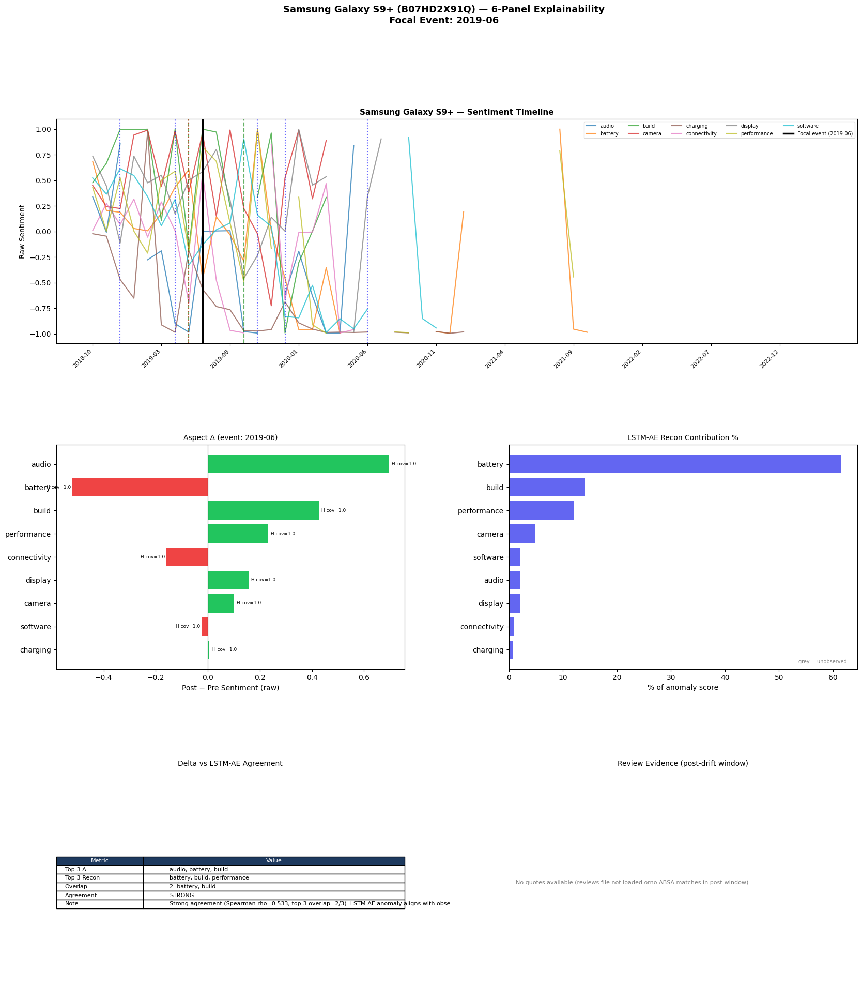

  Event 2019-06: top aspect = audio (delta=+0.695, improvement)
    Agreement: strong, overlap: ['battery', 'build']


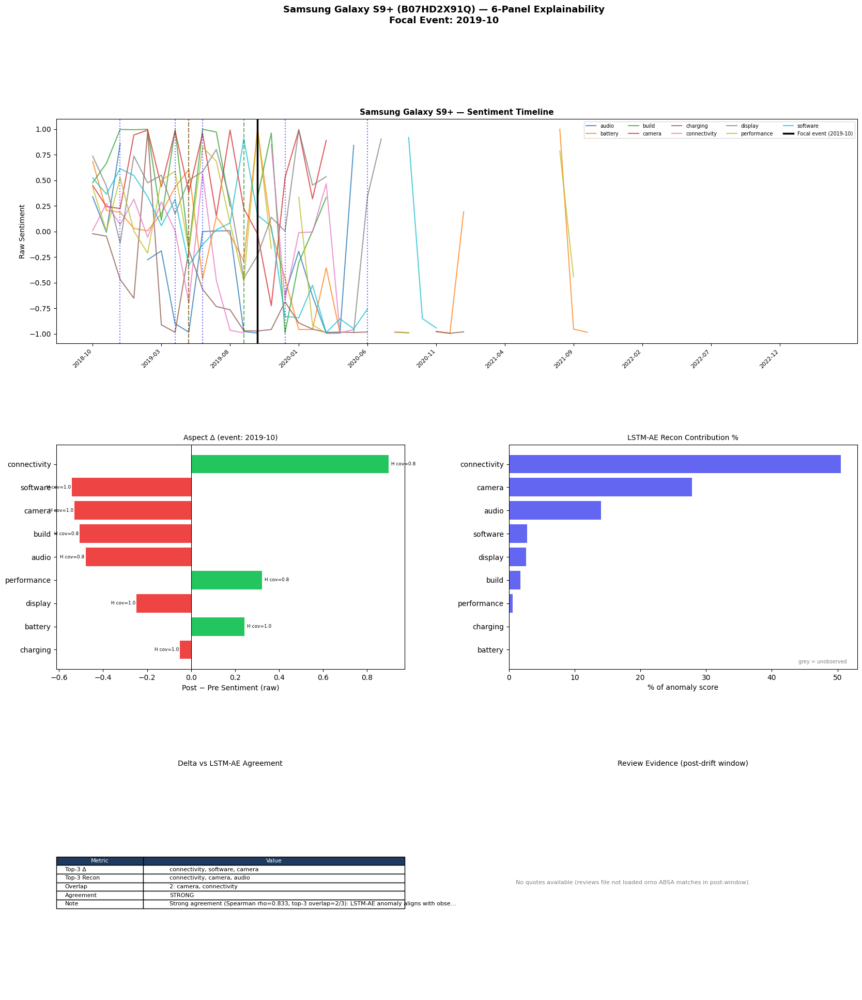

  Event 2019-10: top aspect = connectivity (delta=+0.899, improvement)
    Agreement: strong, overlap: ['camera', 'connectivity']


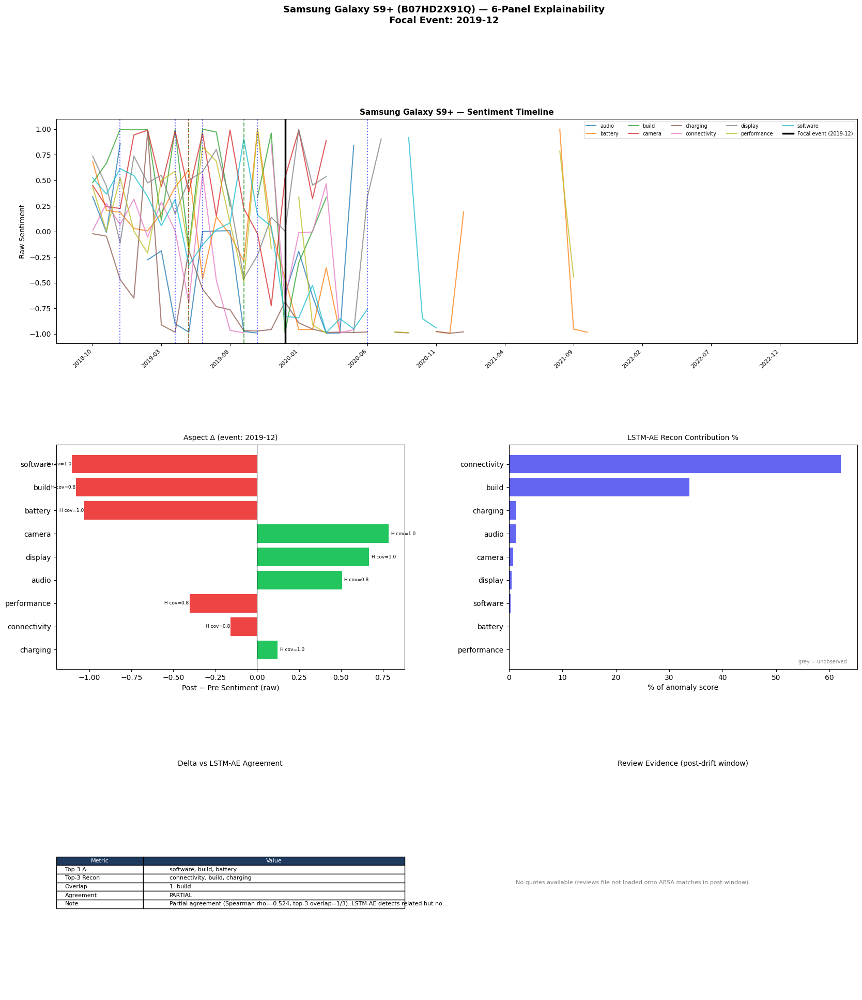

  Event 2019-12: top aspect = software (delta=-1.104, deterioration)
    Agreement: partial, overlap: ['build']


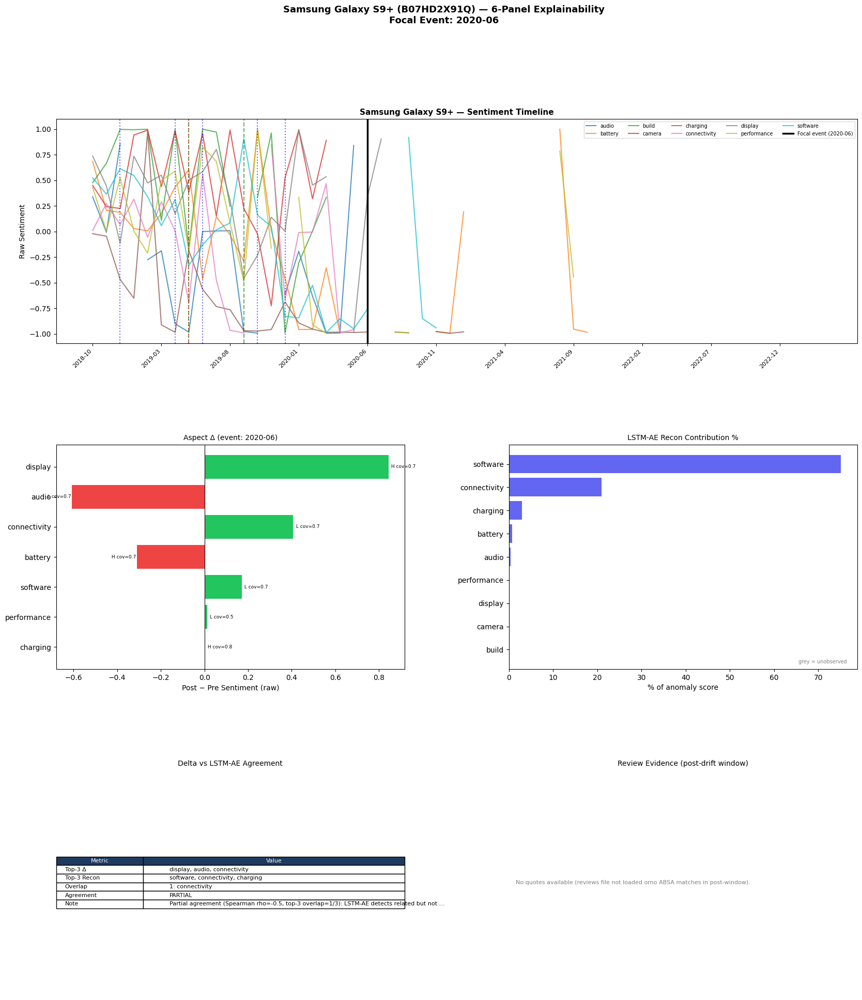

  Event 2020-06: top aspect = display (delta=+0.845, improvement)
    Agreement: partial, overlap: ['connectivity']


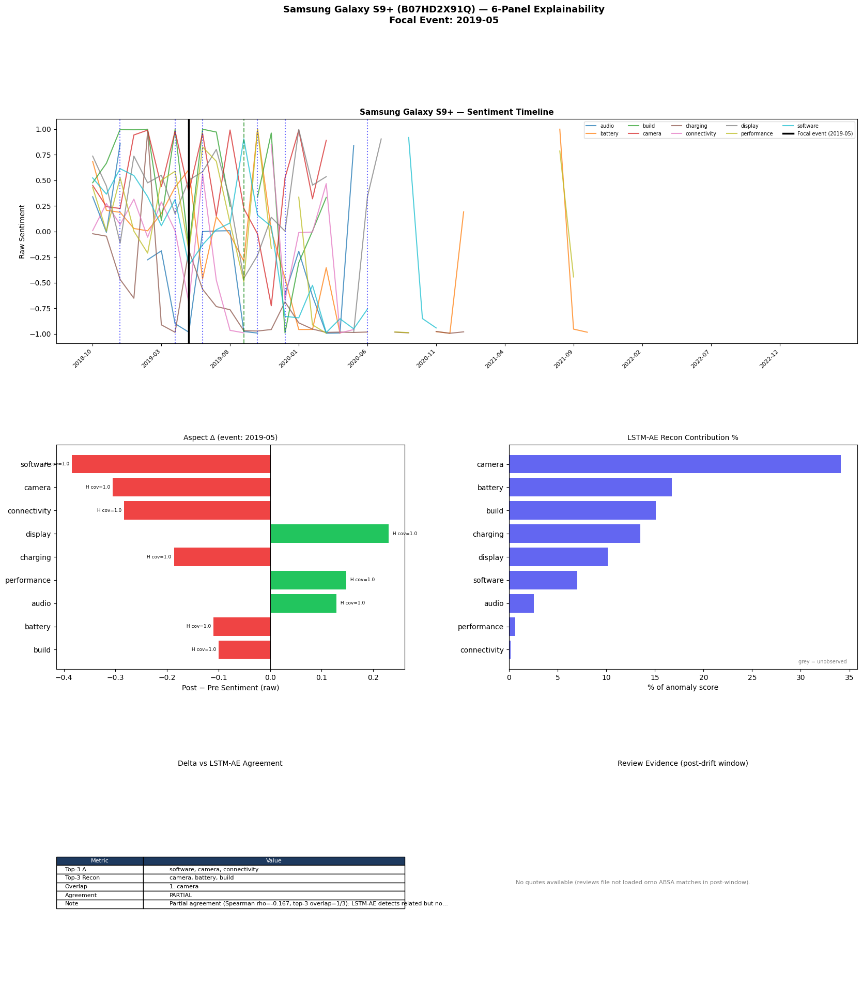

  Event 2019-05: top aspect = software (delta=-0.384, deterioration)
    Agreement: partial, overlap: ['camera']


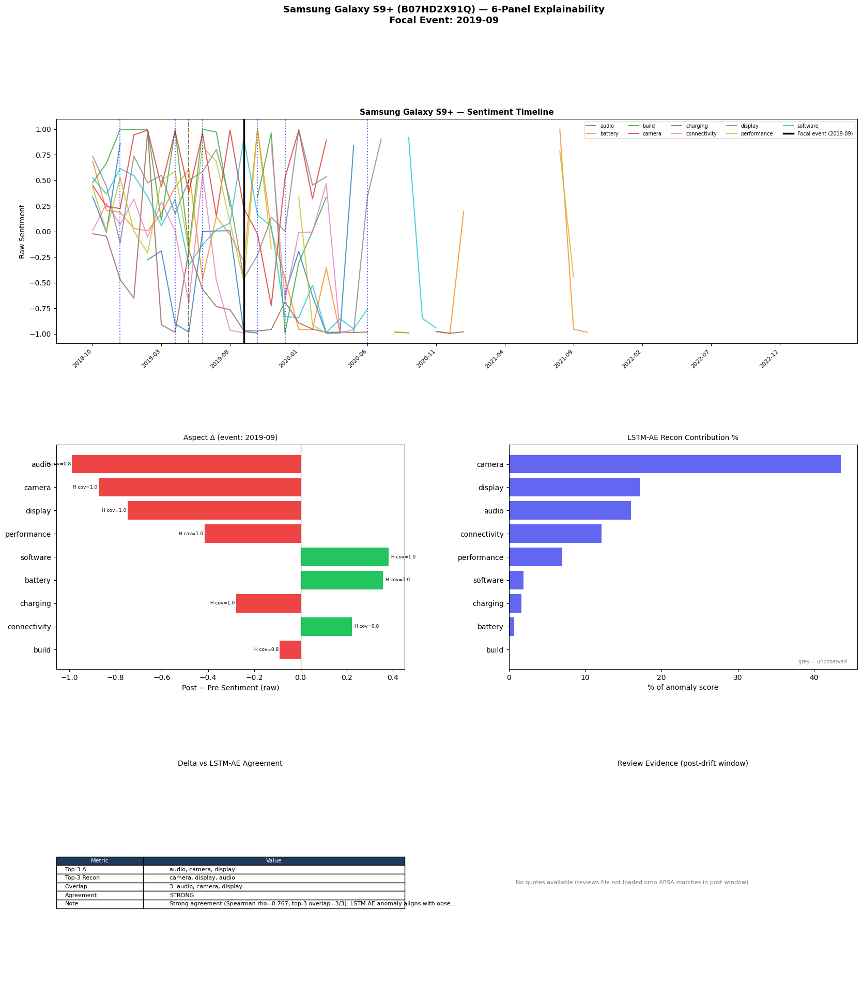

  Event 2019-09: top aspect = audio (delta=-0.988, deterioration)
    Agreement: strong, overlap: ['audio', 'camera', 'display']


In [22]:
# Samsung Galaxy S9+ (B07HD2X91Q)
b07hd2x91q_result, b07hd2x91q_deltas, b07hd2x91q_recon, b07hd2x91q_quotes = analyze_product("B07HD2X91Q")
if b07hd2x91q_result:
    all_results.append(b07hd2x91q_result)
if len(b07hd2x91q_deltas) > 0:
    all_deltas_combined.append(b07hd2x91q_deltas)



Samsung Galaxy S6 (B0178GE72K)
Detected events: 6


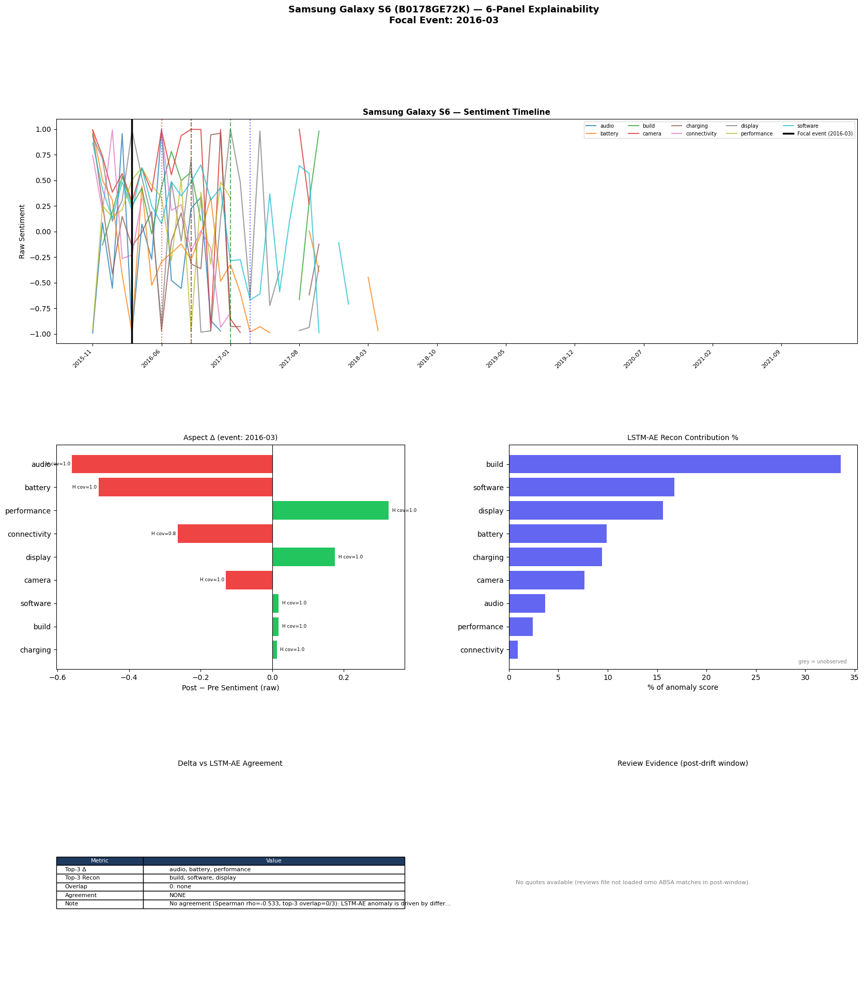

  Event 2016-03: top aspect = audio (delta=-0.559, deterioration)
    Agreement: none, overlap: []


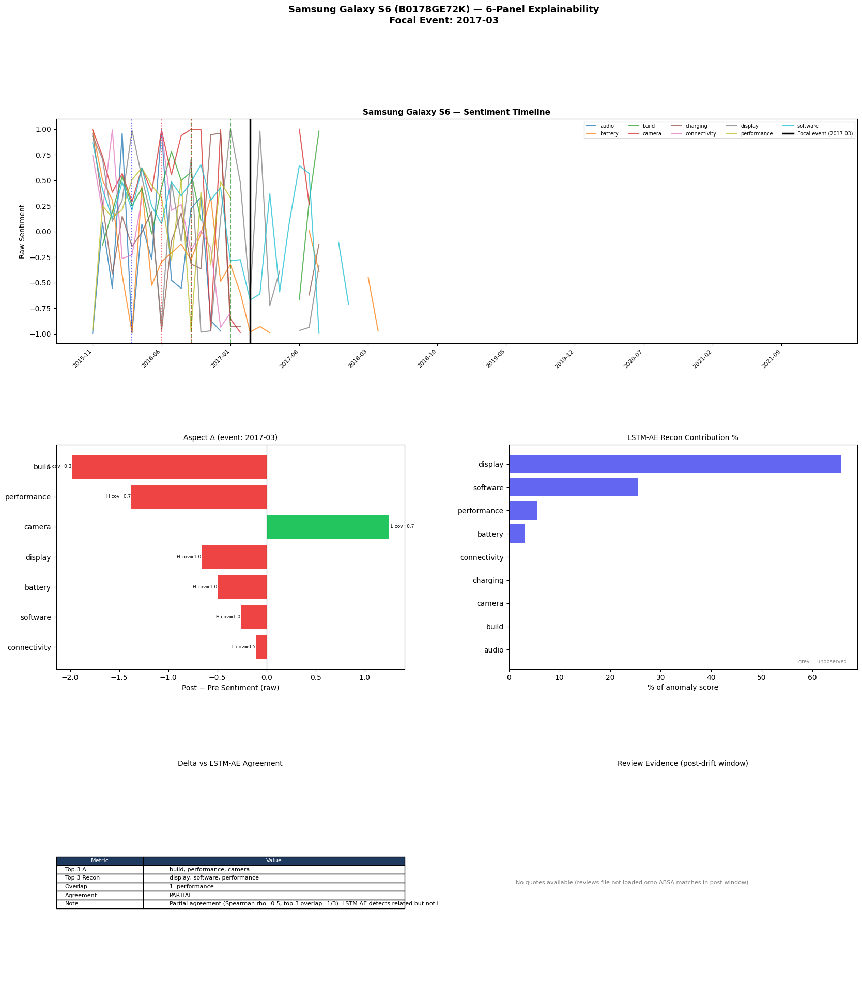

  Event 2017-03: top aspect = build (delta=-1.980, deterioration)
    Agreement: partial, overlap: ['performance']


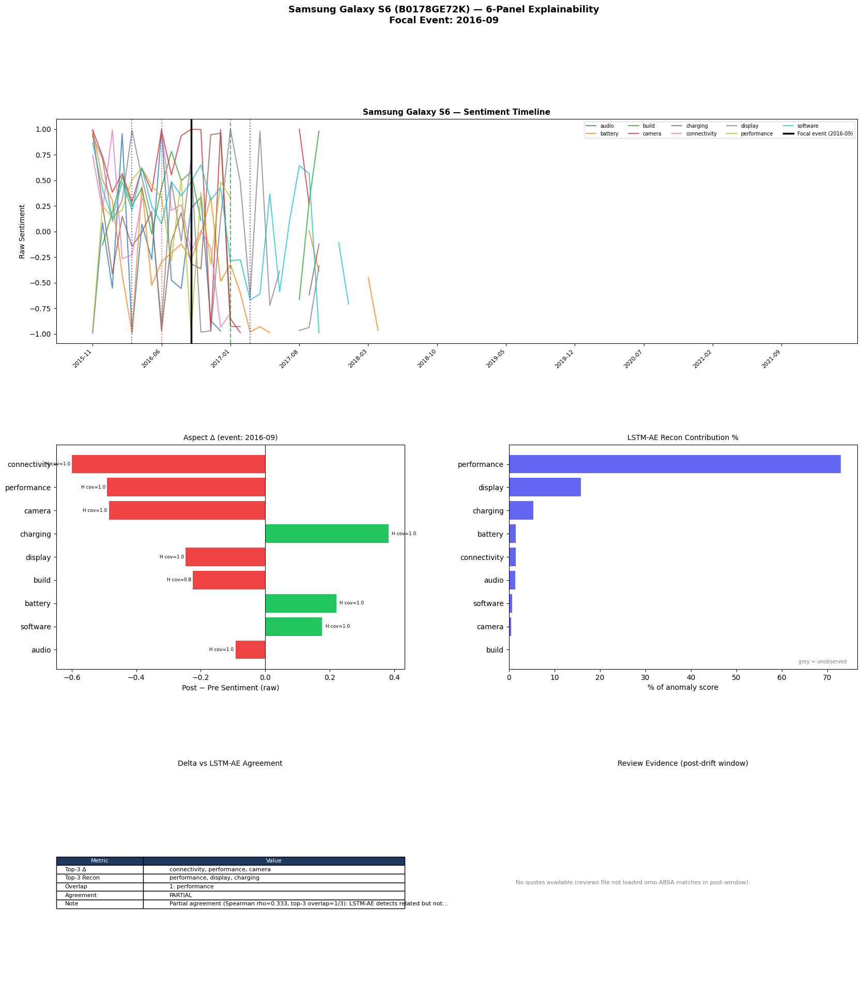

  Event 2016-09: top aspect = connectivity (delta=-0.599, deterioration)
    Agreement: partial, overlap: ['performance']


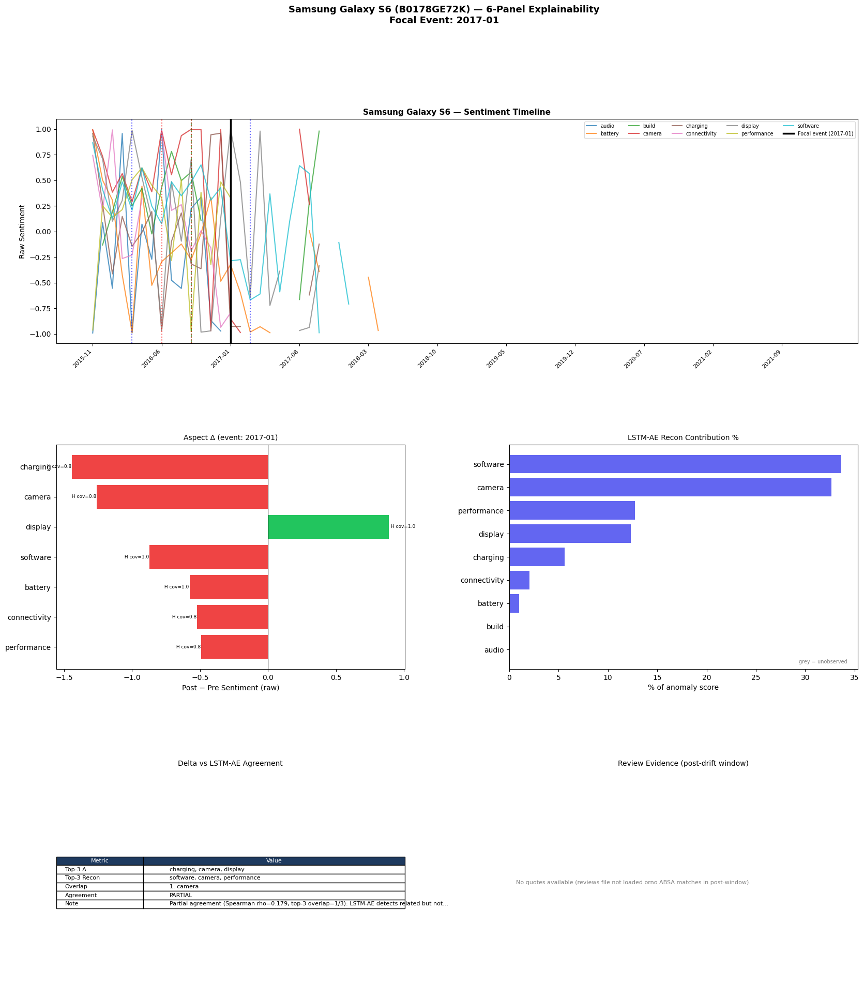

  Event 2017-01: top aspect = charging (delta=-1.441, deterioration)
    Agreement: partial, overlap: ['camera']


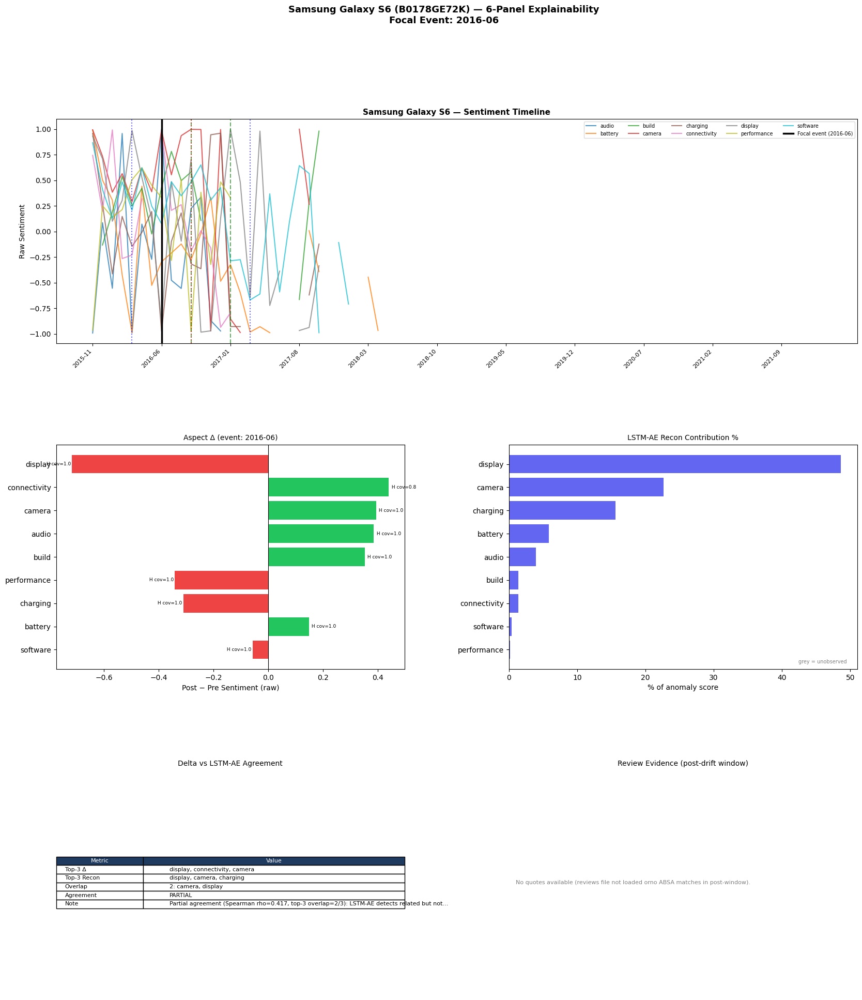

  Event 2016-06: top aspect = display (delta=-0.716, deterioration)
    Agreement: partial, overlap: ['camera', 'display']


In [23]:
# Samsung Galaxy S6 (B0178GE72K)
b0178ge72k_result, b0178ge72k_deltas, b0178ge72k_recon, b0178ge72k_quotes = analyze_product("B0178GE72K")
if b0178ge72k_result:
    all_results.append(b0178ge72k_result)
if len(b0178ge72k_deltas) > 0:
    all_deltas_combined.append(b0178ge72k_deltas)



Samsung Galaxy S6 Edge (B0178GE4FU)
Detected events: 3


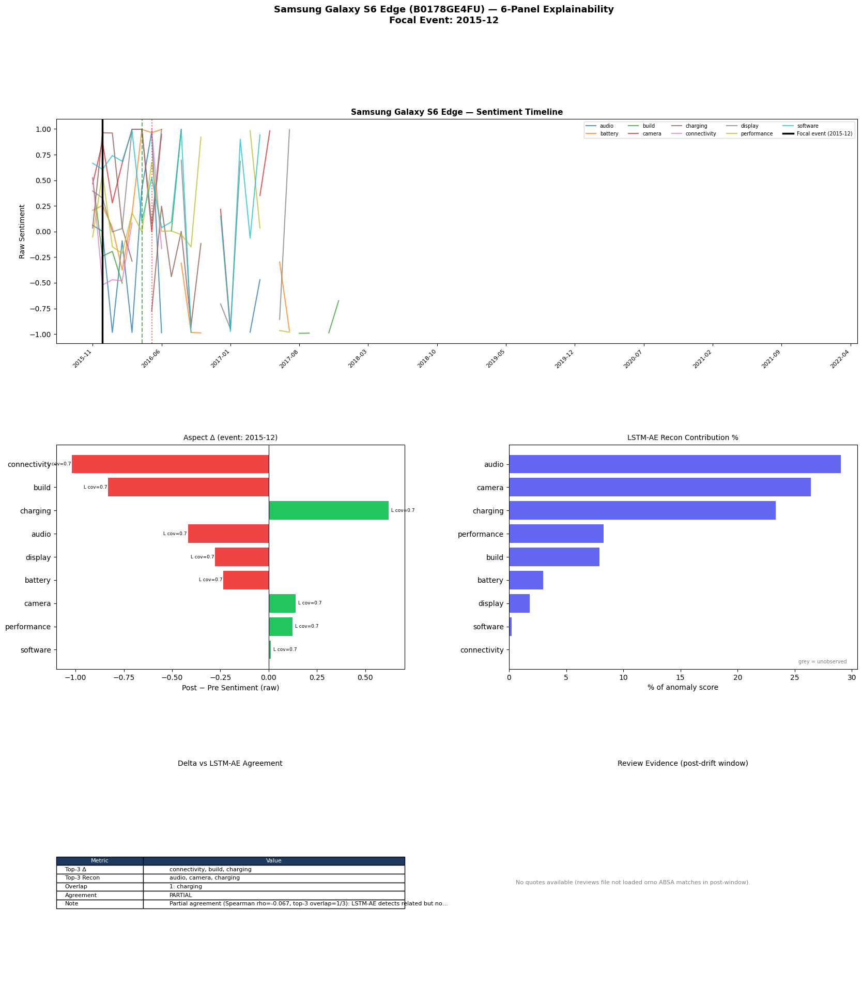

  Event 2015-12: top aspect = connectivity (delta=-1.018, deterioration)
    Agreement: partial, overlap: ['charging']


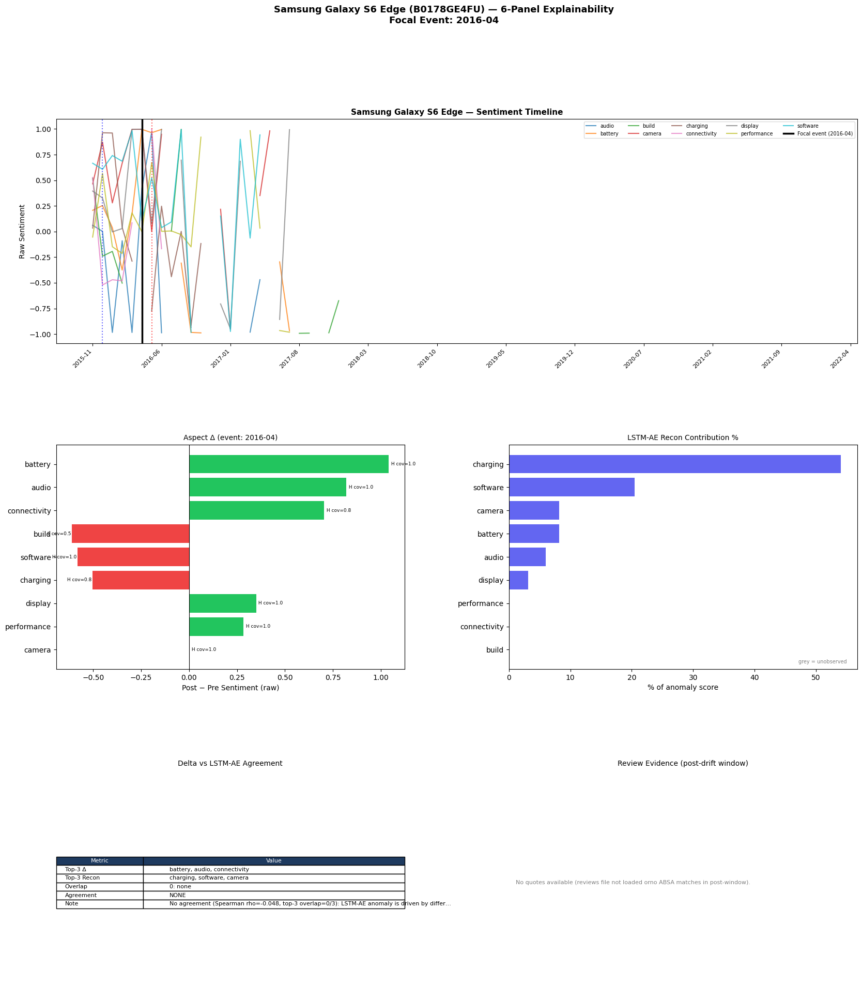

  Event 2016-04: top aspect = battery (delta=+1.041, improvement)
    Agreement: none, overlap: []


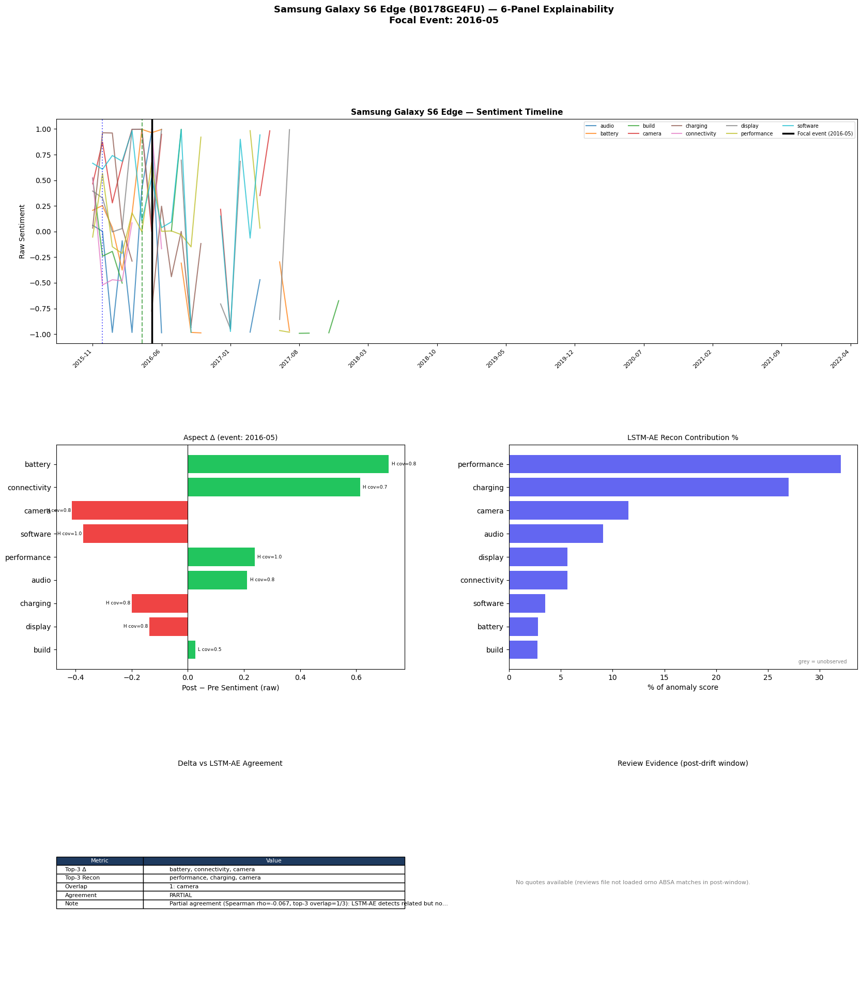

  Event 2016-05: top aspect = battery (delta=+0.716, improvement)
    Agreement: partial, overlap: ['camera']


In [24]:
# Samsung Galaxy S6 Edge (B0178GE4FU)
b0178ge4fu_result, b0178ge4fu_deltas, b0178ge4fu_recon, b0178ge4fu_quotes = analyze_product("B0178GE4FU")
if b0178ge4fu_result:
    all_results.append(b0178ge4fu_result)
if len(b0178ge4fu_deltas) > 0:
    all_deltas_combined.append(b0178ge4fu_deltas)



LG G3 (B00OL4DEMC)
Detected events: 4


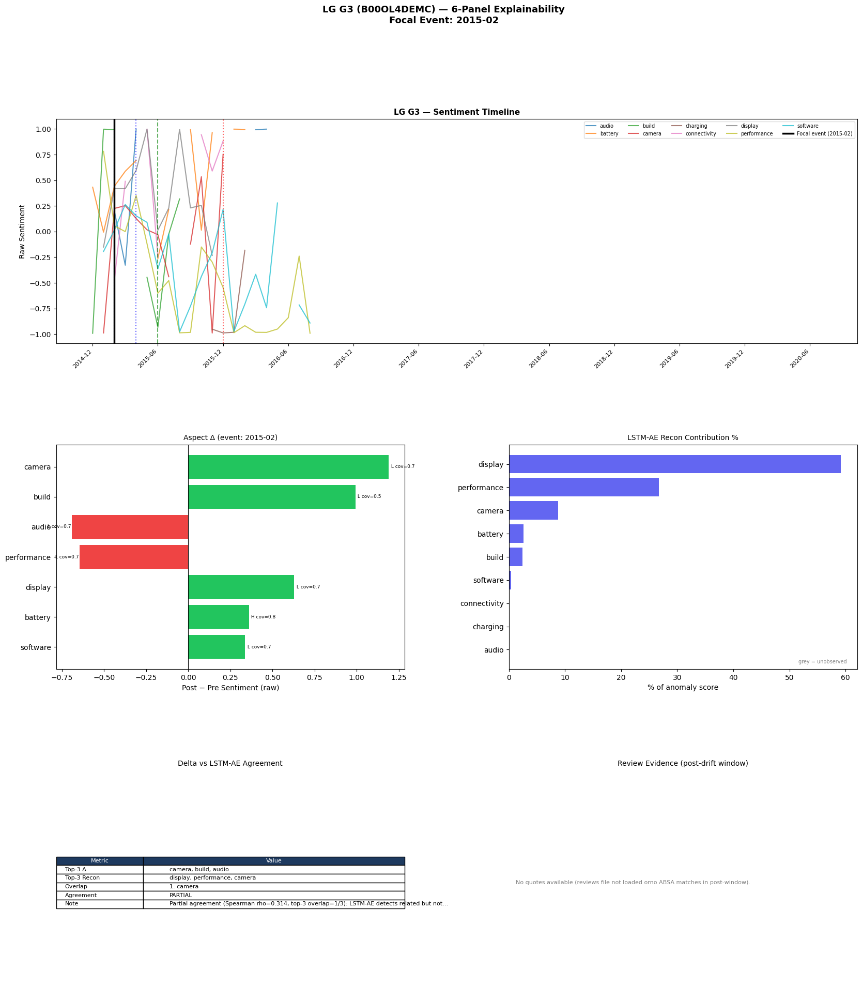

  Event 2015-02: top aspect = camera (delta=+1.190, improvement)
    Agreement: partial, overlap: ['camera']


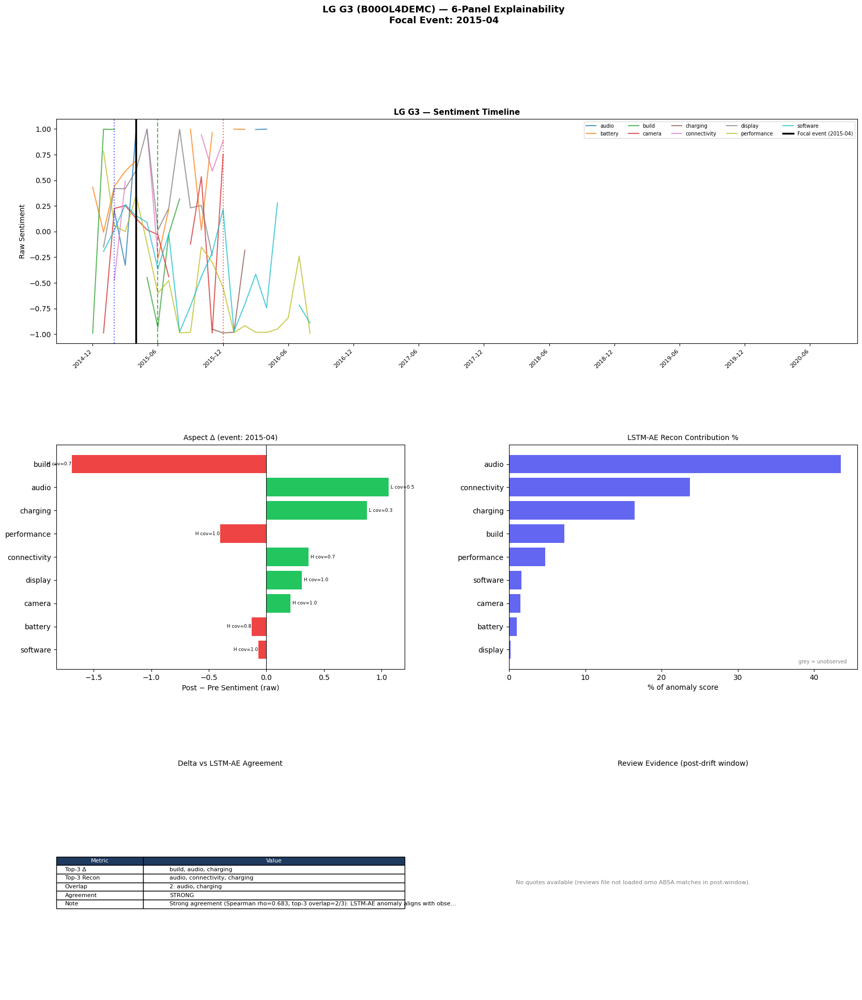

  Event 2015-04: top aspect = build (delta=-1.687, deterioration)
    Agreement: strong, overlap: ['audio', 'charging']


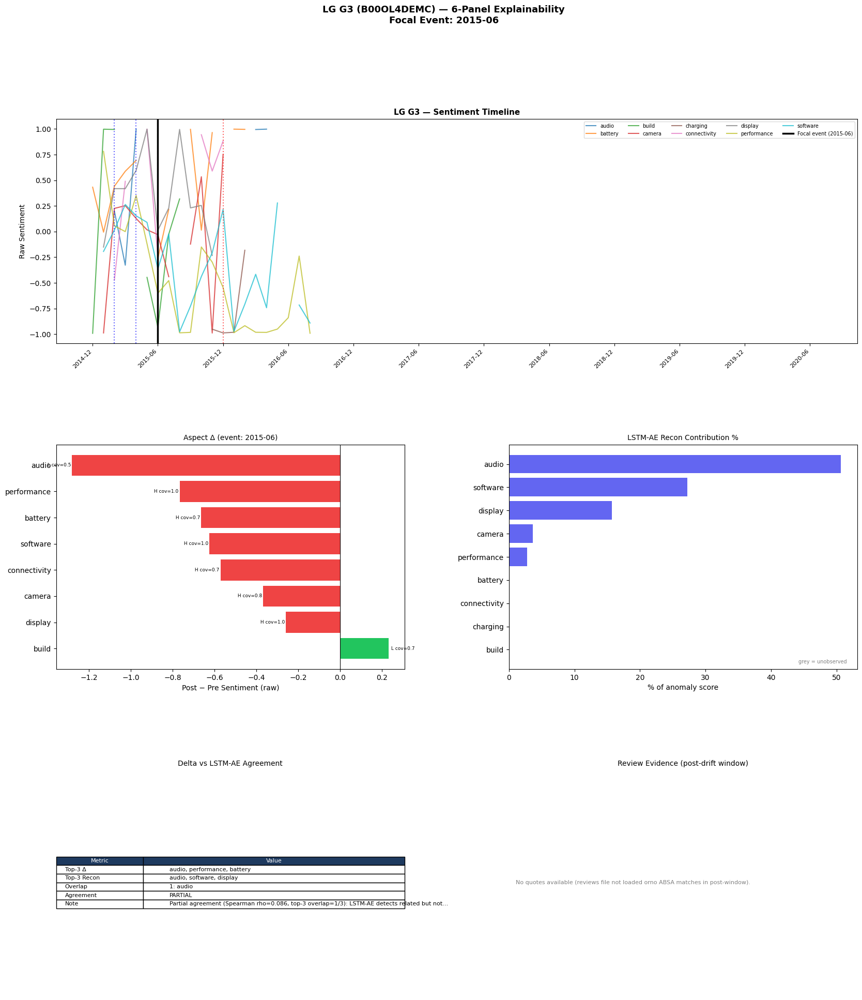

  Event 2015-06: top aspect = audio (delta=-1.280, deterioration)
    Agreement: partial, overlap: ['audio']


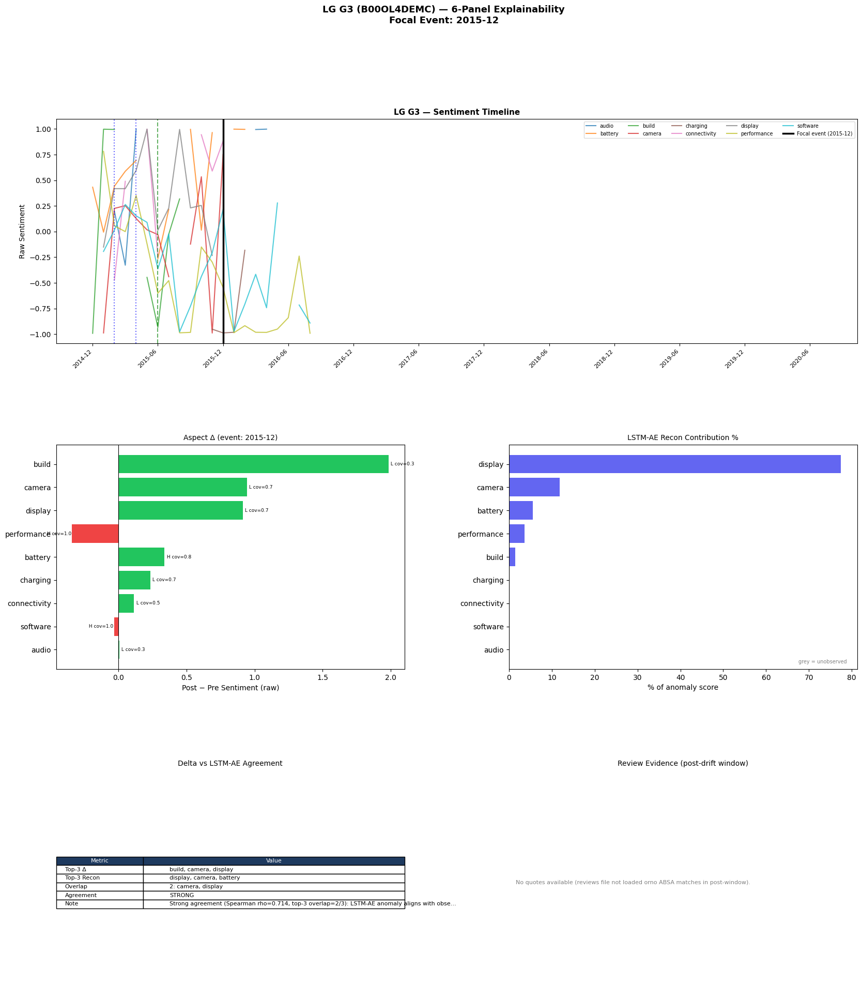

  Event 2015-12: top aspect = build (delta=+1.985, improvement)
    Agreement: strong, overlap: ['camera', 'display']


In [25]:
# LG G3 (B00OL4DEMC)
b00ol4demc_result, b00ol4demc_deltas, b00ol4demc_recon, b00ol4demc_quotes = analyze_product("B00OL4DEMC")
if b00ol4demc_result:
    all_results.append(b00ol4demc_result)
if len(b00ol4demc_deltas) > 0:
    all_deltas_combined.append(b00ol4demc_deltas)



Control (Anker PowerCore) (B01MPXRXR0)
Detected events: 7


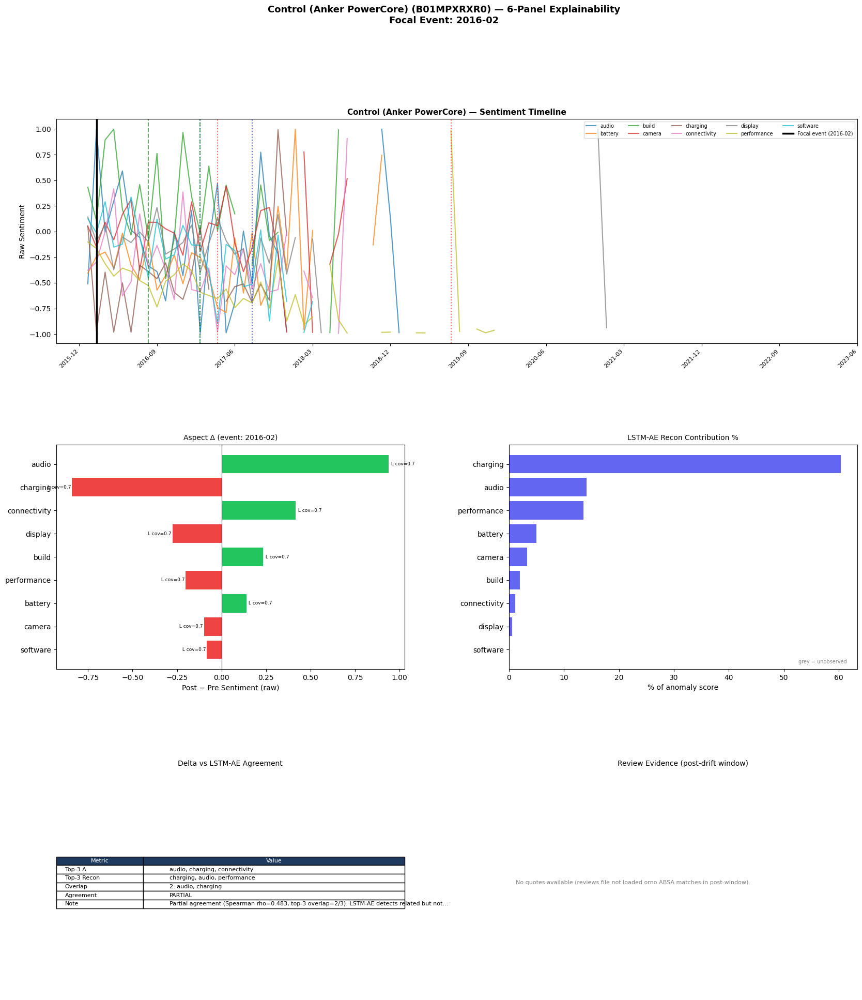

  Event 2016-02: top aspect = audio (delta=+0.939, improvement)
    Agreement: partial, overlap: ['audio', 'charging']


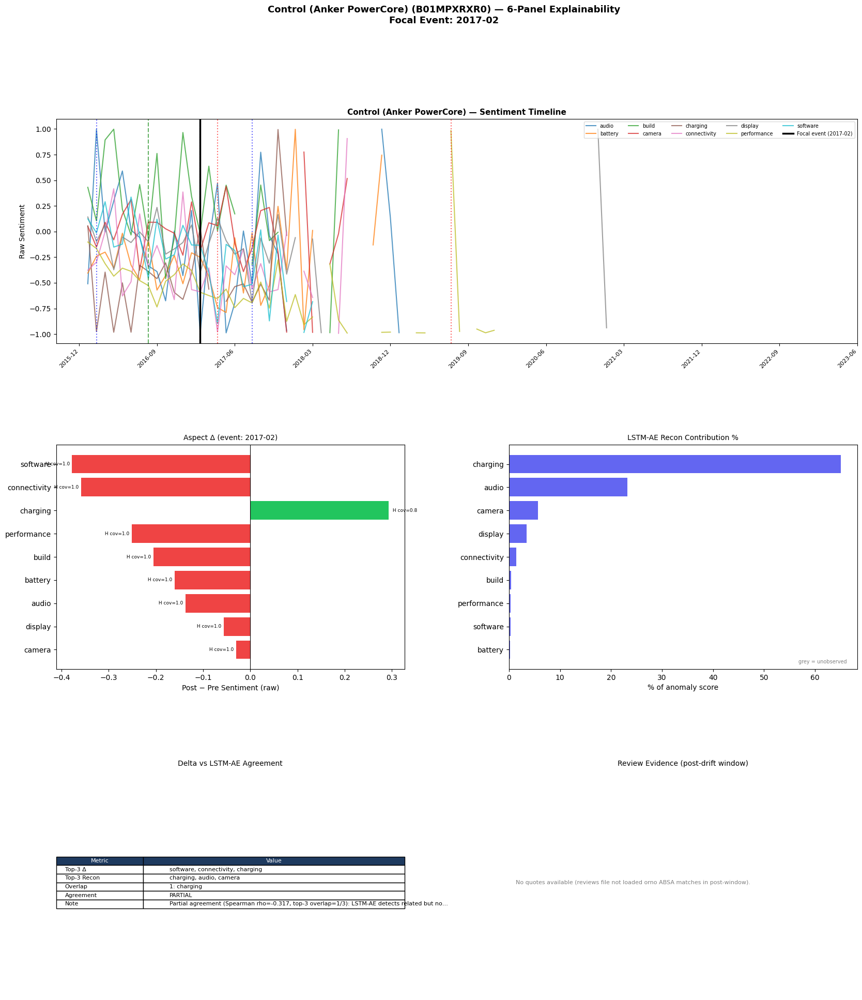

  Event 2017-02: top aspect = software (delta=-0.378, deterioration)
    Agreement: partial, overlap: ['charging']


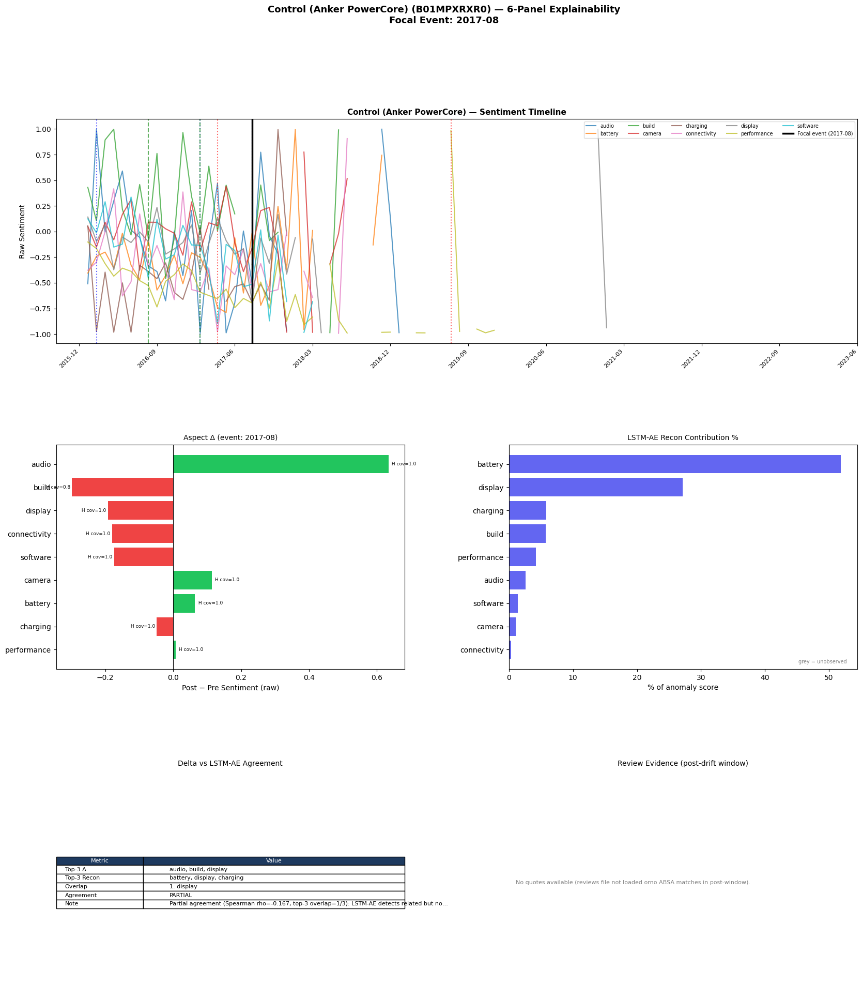

  Event 2017-08: top aspect = audio (delta=+0.635, improvement)
    Agreement: partial, overlap: ['display']


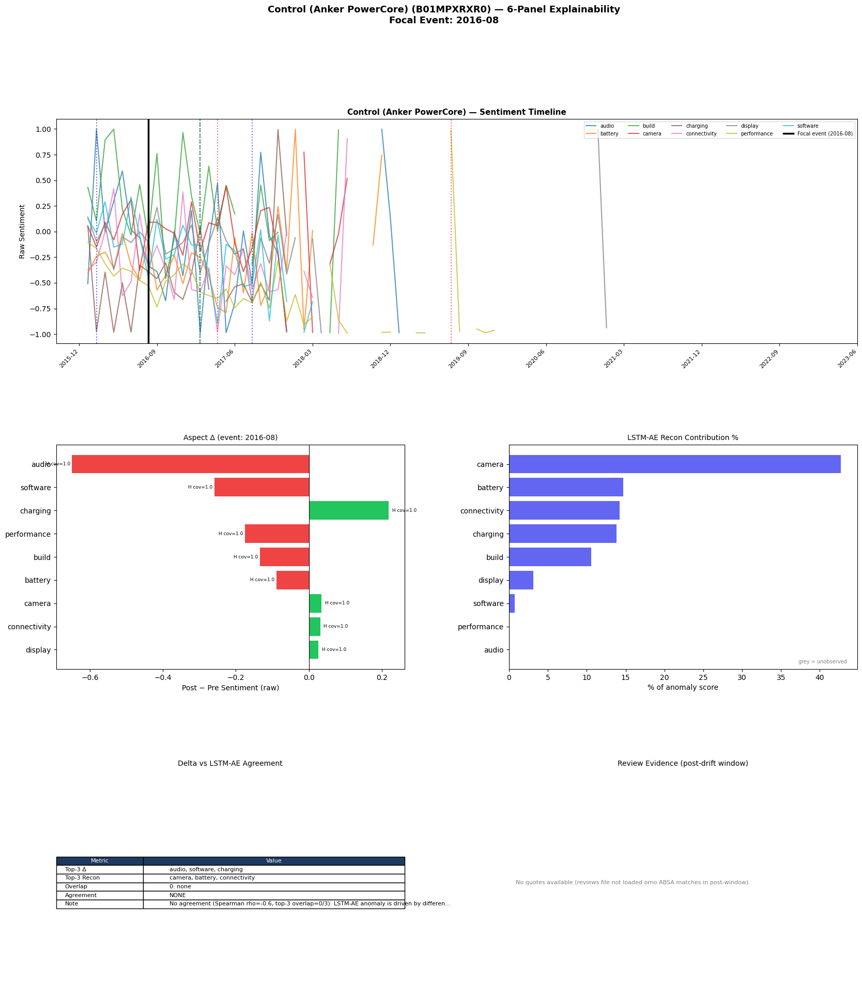

  Event 2016-08: top aspect = audio (delta=-0.649, deterioration)
    Agreement: none, overlap: []


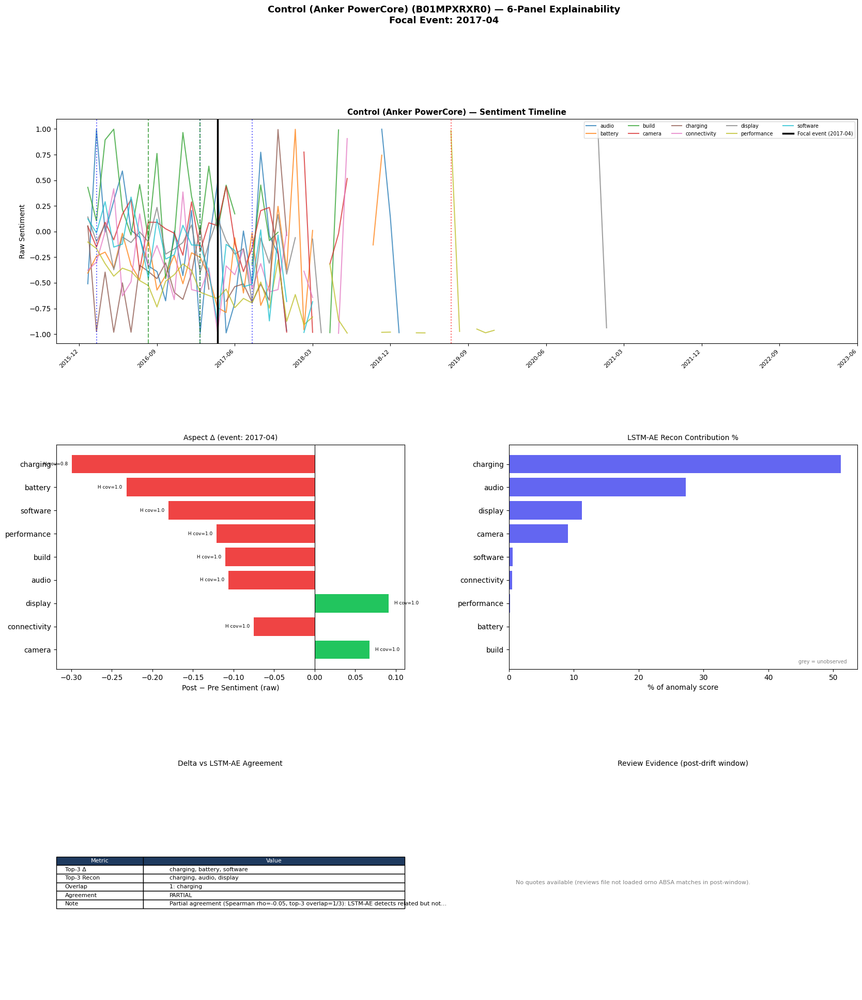

  Event 2017-04: top aspect = charging (delta=-0.299, deterioration)
    Agreement: partial, overlap: ['charging']


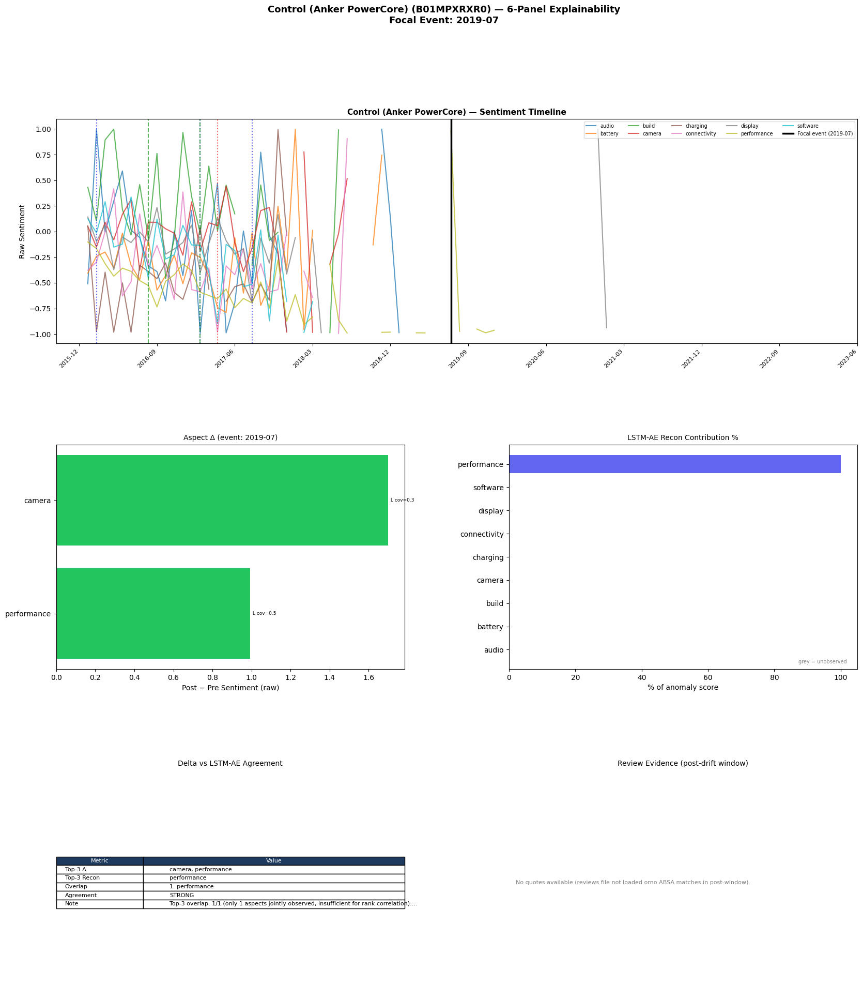

  Event 2019-07: top aspect = camera (delta=+1.699, improvement)
    Agreement: strong, overlap: ['performance']


In [26]:
# Control ASIN — should show no coherent drift story
ctrl_result, ctrl_deltas, ctrl_recon, ctrl_quotes = analyze_product(CONTROL_ASIN)
# Note: control NOT added to all_results (excluded from cross-product synthesis)


In [27]:
# Validate control: deltas should be small
if ctrl_result and len(ctrl_deltas) > 0:
    max_delta = ctrl_deltas["abs_delta"].max()
    print(f"Control max |delta|: {max_delta:.3f}")
    if max_delta < 0.20:
        print("PASS: Control product shows no large drift signal.")
    else:
        print(f"NOTE: Control has delta={max_delta:.3f}. Review manually — may indicate")
        print("      spurious LSTM-AE trigger or genuine product issue.")
else:
    print("Control: No events detected (expected for stable product).")


Control max |delta|: 1.699
NOTE: Control has delta=1.699. Review manually — may indicate
      spurious LSTM-AE trigger or genuine product issue.


---
## Act 5: Cross-Product Synthesis & Industrial Application

We aggregate findings across all 5 case study products to identify:
- Which aspects most commonly drive drift
- How the three detectors complement each other
- Deployment recommendations for production monitoring


In [28]:
# Consolidate results collected during Act 4
all_deltas_all = pd.concat(all_deltas_combined, ignore_index=True) if all_deltas_combined else pd.DataFrame()
print(f"Products in all_results: {len(all_results)}")
print(f"Total events analysed:   {len(all_deltas_all.drop_duplicates(['parent_asin','event_month'])) if len(all_deltas_all) > 0 else 0}")


Products in all_results: 5
Total events analysed:   32


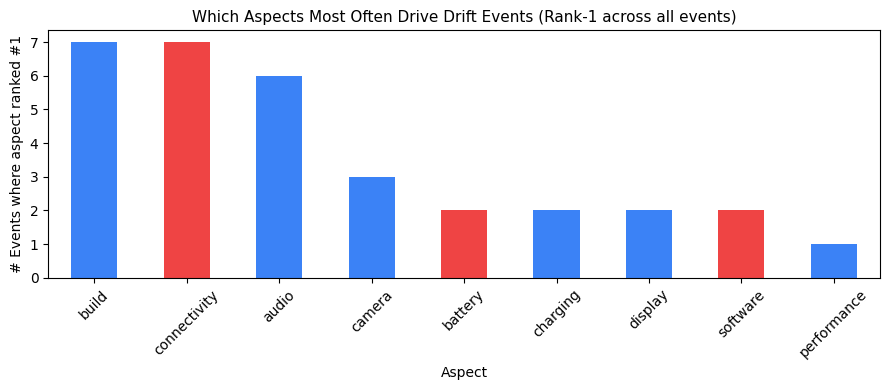

In [29]:
# Aspect frequency — which aspects most often rank #1
if len(all_deltas_all) > 0:
    top_driver = (
        all_deltas_all[all_deltas_all["rank"] == 1]
        .groupby("canonical_aspect")
        .size()
        .sort_values(ascending=False)
    )
    fig, ax = plt.subplots(figsize=(9, 4))
    colors = ["#ef4444" if a in ["battery","software","connectivity"] else "#3b82f6"
              for a in top_driver.index]
    top_driver.plot(kind="bar", ax=ax, color=colors, edgecolor="none")
    ax.set_title("Which Aspects Most Often Drive Drift Events (Rank-1 across all events)",
                 fontsize=11)
    ax.set_xlabel("Aspect")
    ax.set_ylabel("# Events where aspect ranked #1")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "explainability/figures/aspect_frequency.png", dpi=120)
    plt.show()


In [30]:
# Detector complementarity
if len(events_df) > 0:
    det_counts = (
        events_df[events_df["parent_asin"].isin(case_asins)]
        .groupby(["parent_asin", "detector"])
        .size()
        .unstack(fill_value=0)
    )
    det_counts.index = [PRODUCT_NAMES.get(a, a) for a in det_counts.index]
    display(det_counts.style
            .background_gradient(cmap="YlOrRd")
            .set_caption("Detector Complementarity (events per product per detector)"))


detector,CUSUM,LSTM-AE,PELT
LG G3,2,1,1
Samsung Galaxy S6 Edge,1,1,1
Samsung Galaxy S6,2,2,2
Google Nexus 6P,9,2,3
Samsung Galaxy S9+,6,1,2


### Honest Comparison: CUSUM vs LSTM-AE vs PELT

**CUSUM (57.0% recall, 1.11-month delay)** performs best on this dataset.
This is expected: CUSUM detects *sustained level shifts* in individual aspects,
which is the dominant pattern when product quality genuinely changes.

**LSTM-AE (33.5% recall, 0.69-month delay)** has faster detection but lower recall.
It fires on *shape/volatility anomalies* in the latent representation — useful for
early warning of transient events (sudden spikes) even when the level hasn't shifted.
The LSTM-AE's strength is *speed*, not coverage.

**PELT (22.5% recall)** is the weakest here. CostRank changepoint detection on
sparse, noisy monthly data struggles to reach statistical significance.

**Industrial recommendation:** Hybrid monitoring — CUSUM as the primary alarm
(higher confidence), LSTM-AE as an early-warning system (faster response).


In [31]:
# Priority action items table
action_rows = []
for r in all_results:
    for item in r.get("action_items", []):
        action_rows.append({
            "Product": PRODUCT_NAMES.get(r["parent_asin"], r["parent_asin"]),
            "Event": item.get("event_month", ""),
            "Aspect": item.get("aspect", ""),
            "Severity": item.get("severity", ""),
            "Direction": item.get("direction", ""),
            "Evidence": item.get("evidence_strength", ""),
        })

if action_rows:
    action_df = pd.DataFrame(action_rows)
    severity_color = lambda x: "background-color: #fee2e2" if x == "high" else ""
    display(
        action_df.sort_values(["Severity", "Product"])
        .style
        .applymap(severity_color, subset=["Severity"])
        .set_caption("Prioritised Action Items Across All Products")
    )
else:
    print("No action items (no events detected).")


,Product,Event,Aspect,Severity,Direction,Evidence
19,Samsung Galaxy S6 Edge,,audio,0.417950,deterioration,low
18,Samsung Galaxy S6 Edge,,charging,0.501896,deterioration,high
4,Google Nexus 6P,,battery,0.569917,deterioration,high
17,Samsung Galaxy S6 Edge,,software,0.580408,deterioration,high
24,LG G3,,software,0.623614,deterioration,high
23,LG G3,,battery,0.663864,deterioration,high
22,LG G3,,performance,0.766199,deterioration,high
3,Google Nexus 6P,,performance,0.786900,deterioration,high
16,Samsung Galaxy S6 Edge,,build,0.831745,deterioration,low
14,Samsung Galaxy S6,,software,0.871174,deterioration,high


---
## Act 6: Limitations, Critical Reflection & Export

### Limitations

1. **Sparsity (72% missing):** Many aspect-month cells have no observations.
   Window-based analysis is unreliable for aspects with < 2 observations per window.
2. **ABSA noise (F1=0.883):** ~12% of aspect labels may be incorrect.
   Errors are non-uniform — rare aspects are more likely to be misclassified.
3. **Selection bias:** Only 5 case study ASINs were hand-selected. Findings may
   not generalise to all product categories.
4. **Window sensitivity:** Deltas vary with window size (w=2,3,4). We report w=3
   as a compromise, but the choice is partially arbitrary.
5. **Reverse causality:** A detected "drift event" may be preceded by an
   anticipatory change in sentiment (e.g. rumour of a product recall).

### Why CUSUM Beats LSTM-AE

CUSUM's dominance reflects the *nature of the data*: sparse monthly aggregates of
product reviews exhibit clear level shifts when quality changes, not complex
temporal dependencies. The LSTM-AE's advantage (fast detection, shape sensitivity)
is less valuable when reviews accumulate slowly and the signal is coarse.

In a streaming context with daily data and higher review density, the LSTM-AE's
latent-space anomaly detection would likely be more competitive.

### Future Work (Deferred)

- **Captum Integrated Gradients** on the PyABSA model for within-sentence attribution.
- **Amazon-domain HF model** (ABSA) for higher aspect-extraction fidelity.
- **Batched inference pipeline** for production monitoring of 328+ products.
- **Double-labelling** of gold standard to measure inter-annotator agreement.


In [32]:
# Export all results
if all_results:
    export_paths = export_results(
        all_results,
        all_deltas_all,
        events_df,
        output_dir=str(RESULTS_DIR / "explainability"),
        dashboard_dir=str(Path("..") / "dashboard" / "react" / "public" / "data"),
    )
    for k, v in export_paths.items():
        print(f"  {k}: {v}")
else:
    print("WARNING: No results to export -- no events detected on any product.")


  product_B019BX7F86: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\product_B019BX7F86.json
  product_B07HD2X91Q: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\product_B07HD2X91Q.json
  product_B0178GE72K: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\product_B0178GE72K.json
  product_B0178GE4FU: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\product_B0178GE4FU.json
  product_B00OL4DEMC: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\product_B00OL4DEMC.json
  summary: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\summary.json
  detection_events: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\detection_events.parquet
  aspect_deltas: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\results\explainability\aspect_delta

In [33]:
# Validate JSON export
import json
bundle_path = Path("dashboard/react/public/data/explainability.json")
if bundle_path.exists():
    with open(bundle_path, encoding="utf-8") as f:
        bundle = json.load(f)
    print(f"Bundle valid. Products: {len(bundle['products'])}")
    for p in bundle["products"]:
        print(f"  {p['parent_asin']} ({p['product_name']}): "
              f"{p['n_events']} events, {len(p['timeline'])} timeline months")
else:
    print("Bundle not yet written (no results). Run export_results() above.")


Bundle not yet written (no results). Run export_results() above.


In [34]:
# Final notebook validation
print("=" * 60)
print("Phase 4 Explainability notebook complete.")
print("=" * 60)
print(f"  Products analysed: {len(all_results)}")
print(f"  Events explained:  {len(all_deltas_all.drop_duplicates(['parent_asin','event_month'])) if len(all_deltas_all) > 0 else 0}")
print()
print("Outputs:")
print(f"  results/explainability/       - JSON + parquet per product")
print(f"  results/explainability/figures/ - PNG figures")
print(f"  dashboard/react/public/data/explainability.json - React bundle")


Phase 4 Explainability notebook complete.
  Products analysed: 5
  Events explained:  32

Outputs:
  results/explainability/       - JSON + parquet per product
  results/explainability/figures/ - PNG figures
  dashboard/react/public/data/explainability.json - React bundle


## Token-level attribution (Captum Integrated Gradients)

Complements the aspect-delta ranking with a gradient-based explanation of *which words in a review drove the predicted aspect sentiment*. Uses `LayerIntegratedGradients` over the PyABSA transformer's embedding layer.

**Requires:** CUDA for reasonable runtime, PyABSA classifier already loaded.
**Output:** per-review heatmap PNGs saved to `results/explainability/figures/ig_*.png`.

In [35]:
# Demo: run Captum IG on three case-study reviews (one per sentiment class).
from src.explain.captum_ig import compute_attributions, render_heatmap
from pathlib import Path

OUT_DIR = Path("../results/explainability/figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)

demo_reviews = [
    ("The battery dies after only 2 hours. I need to charge it constantly.", "battery"),
    ("The camera is still excellent; photos look great in daylight.",        "camera"),
    ("Software update made everything slower and the phone restarts randomly.", "software"),
]

for text, aspect in demo_reviews:
    attr = compute_attributions(text=text, aspect=aspect, n_steps=50)
    render_heatmap(attr, save_to=OUT_DIR / f"ig_{aspect}.png")
    print(f"{aspect:>10}  →  {attr['predicted_label']:>8}  (p={attr['confidence']:.2f})")


<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute


<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute


C:\Users\alexi\Anaconda3\envs\aidl\Lib\site-packages\torch\jit\_script.py:1480: DeprecationWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[2026-04-19 21:59:11] (2.4.2)

PyABSA(2.4.2): If your code crashes on Colab, please use the GPU runtime. Then run "pip install pyabsa[dev] -U" and restart the kernel.
Or if it does not work, you can use v1.x versions, e.g., pip install pyabsa<2.0 -U




Try to downgrade transformers<=4.29.0.





[2026-04-19 21:59:12] (2.4.2)

... (32 outputs left out)

[2026-04-19 21:59:17] (2.4.2)

    camera  →  positive  (p=1.00)

[2026-04-19 21:59:18] (2.4.2)

  software  →  negative  (p=0.99)